# COS801 Aligned Pruning, Quantisation and Knowledge Distillation

This standalone Colab notebook forces pruning and quantisation through the **same dataset, class mapping, baseline checkpoint, evaluation function, model-size method, and CPU latency benchmark**. It also includes knowledge distillation (KD) as a recovery strategy for a pruned student.

The key control is the **baseline parity gate**: each branch must reproduce the same FP32 baseline metrics before compressed results are compared.


## 1. Imports, seed and Drive paths

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('sklearn') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn'])

import copy, json, os, random, time, urllib.parse
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.nn.utils.prune as prune
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, mobilenet_v3_small
from torch.ao.quantization import (
    FakeQuantize, HistogramObserver, MinMaxObserver,
    MovingAverageMinMaxObserver, MovingAveragePerChannelMinMaxObserver,
    PerChannelMinMaxObserver, QConfig, QConfigMapping, disable_observer,
)
from torch.ao.quantization.quantize_fx import prepare_fx, prepare_qat_fx, convert_fx
from google.colab import drive

SEED=42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
set_seed()
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',device,'PyTorch:',torch.__version__)

drive.mount('/content/drive')
PROJECT_DIR=Path('/content/drive/Shareddrives/COS 801 Group 6')
IMG_BASE_DIR=PROJECT_DIR/'data'/'raw'
SPLIT_CSV=PROJECT_DIR/'data'/'data_split_resolved.csv'
MODEL_DIR=PROJECT_DIR/'models'
RESULTS_DIR=PROJECT_DIR/'results'/'aligned_compression_partial'
OUTPUT_MODEL_DIR=MODEL_DIR/'aligned_compression_partial'
RESULTS_DIR.mkdir(parents=True,exist_ok=True)
OUTPUT_MODEL_DIR.mkdir(parents=True,exist_ok=True)

Device: cpu PyTorch: 2.11.0+cpu
Mounted at /content/drive


## 2. One shared class mapping and split definition

In [ ]:
SHARED_CLASSES={
'apple_scab':('Apple___Apple_scab','Apple Scab Leaf'),'apple_rust':('Apple___Cedar_apple_rust','Apple rust leaf'),
'apple_healthy':('Apple___healthy','Apple leaf'),'blueberry_healthy':('Blueberry___healthy','Blueberry leaf'),
'cherry_healthy':('Cherry_(including_sour)___healthy','Cherry leaf'),
'corn_gray_spot':('Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot','Corn Gray leaf spot'),
'corn_rust':('Corn_(maize)___Common_rust_','Corn rust leaf'),'corn_blight':('Corn_(maize)___Northern_Leaf_Blight','Corn leaf blight'),
'grape_black_rot':('Grape___Black_rot','grape leaf black rot'),
'grape_healthy':('Grape___healthy','grape leaf'),'peach_healthy':('Peach___healthy','Peach leaf'),
'pepper_healthy':('Pepper,_bell___healthy','Bell_pepper leaf'),
'potato_early_blight':('Potato___Early_blight','Potato leaf early blight'),
'potato_late_blight':('Potato___Late_blight','Potato leaf late blight'),
'raspberry_healthy':('Raspberry___healthy','Raspberry leaf'),'soybean_healthy':('Soybean___healthy','Soyabean leaf'),
'squash_mildew':('Squash___Powdery_mildew','Squash Powdery mildew leaf'),
'strawberry_healthy':('Strawberry___healthy','Strawberry leaf'),
'tomato_bacterial_spot':('Tomato___Bacterial_spot','Tomato leaf bacterial spot'),
'tomato_early_blight':('Tomato___Early_blight','Tomato Early blight leaf'),
'tomato_late_blight':('Tomato___Late_blight','Tomato leaf late blight'),'tomato_leaf_mold':('Tomato___Leaf_Mold','Tomato mold leaf'),
'tomato_septoria':('Tomato___Septoria_leaf_spot','Tomato Septoria leaf spot'),
'tomato_yellow_virus':('Tomato___Tomato_Yellow_Leaf_Curl_Virus','Tomato leaf yellow virus'),
'tomato_mosaic_virus':('Tomato___Tomato_mosaic_virus','Tomato leaf mosaic virus'),'tomato_healthy':('Tomato___healthy','Tomato leaf')}
CLASS_NAMES=tuple(SHARED_CLASSES)
CLASS_TO_IDX={name:i for i,name in enumerate(CLASS_NAMES)}
N_CLASSES=len(CLASS_NAMES)

df=pd.read_csv(SPLIT_CSV)
PATH_COLUMN='path' if 'path' in df.columns else 'resolved_path'
required={'split','class',PATH_COLUMN}
if not required.issubset(df.columns): raise ValueError(f'Missing columns: {required-set(df.columns)}')
df=df[df['class'].isin(CLASS_NAMES)].copy()

# Limit the training set (PlantVillage) to only rows where use_50pct is True
if 'use_50pct' in df.columns:
    # Only apply the filter on the 'train' split which represents our PlantVillage training dataset
    train_mask = df.split.eq('train') & (df['use_50pct'] == True)
    non_train_mask = ~df.split.eq('train')
    df = df[train_mask | non_train_mask].reset_index(drop=True)
else:
    raise ValueError("The column 'use_50pct' was not found in the split CSV metadata.")

train_df=df[df.split.eq('train')].reset_index(drop=True)
val_df=df[df.split.eq('val')].reset_index(drop=True)
test_df=df[df.split.eq('test')].reset_index(drop=True)
field_df=df[df.split.eq('field_test')].reset_index(drop=True)
print({k:len(v) for k,v in [('train',train_df),('val',val_df),('test',test_df),('field_test',field_df)]})

{'train': 12624, 'val': 5385, 'test': 5376, 'field_test': 2499}


## 3. One shared Dataset and DataLoader pipeline

Evaluation loaders are deterministic. Missing or corrupt images raise an error instead of being replaced or randomly substituted.

In [ ]:
import io
import math
import random
from PIL import Image, ImageDraw, ImageFilter
import numpy as np
import torch
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
GREY = (128, 128, 128)

# --- Custom Augmentation Classes ---

class RandomGamma:
    def __init__(self, p=0.5, lo=0.6, hi=1.6):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        g = math.exp(random.uniform(math.log(self.lo), math.log(self.hi)))
        lut = [min(255, int(255 * (i / 255) ** g + 0.5)) for i in range(256)]
        return img.point(lut * len(img.getbands()))


class RandomShadow:
    """A soft dark polygon: canopy leaves shading each other."""
    def __init__(self, p=0.4, strength=(0.45, 0.8)):
        self.p, self.strength = p, strength

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        cx, cy = random.uniform(0, w), random.uniform(0, h)
        r = random.uniform(0.25, 0.6) * max(w, h)
        pts = [(cx + r * random.uniform(0.5, 1.0) * math.cos(a), cy + r * random.uniform(0.5, 1.0) * math.sin(a))
               for a in sorted(random.uniform(0, 2 * math.pi) for _ in range(random.randint(4, 7)))]
        mask = Image.new("L", (w, h), 0)
        ImageDraw.Draw(mask).polygon(pts, fill=255)
        mask = mask.filter(ImageFilter.GaussianBlur(max(1, 0.03 * max(w, h))))
        k = random.uniform(*self.strength)
        dark = img.point(lambda v: int(v * k))
        return Image.composite(dark, img, mask)


class RandomDownscale:
    def __init__(self, p=0.5, lo=0.25, hi=0.7):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        f = random.uniform(self.lo, self.hi)
        return img.resize((max(8, int(w * f)), max(8, int(h * f))), Image.BILINEAR).resize((w, h), Image.BILINEAR)


class RandomJPEG:
    def __init__(self, p=0.5, lo=25, hi=85):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        buf = io.BytesIO()
        img.save(buf, "JPEG", quality=random.randint(self.lo, self.hi))
        buf.seek(0)
        return Image.open(buf).convert("RGB")


class GaussianNoise:
    """On a [0, 1] tensor, before normalisation."""
    def __init__(self, p=0.5, lo=0.01, hi=0.05):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, x):
        if random.random() > self.p:
            return x
        return (x + torch.randn_like(x) * random.uniform(self.lo, self.hi)).clamp(0, 1)


class RotateShearBorderFill:
    """Rotation + shear filled with the image's own border colour (median of the edge pixels)."""
    def __init__(self, degrees=30, shear=10):
        self.degrees, self.shear = degrees, shear

    def __call__(self, img):
        a = np.asarray(img)
        edge = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
        fill = tuple(int(v) for v in np.median(edge, 0))
        return T.RandomAffine(self.degrees, shear=self.shear, fill=fill)(img)


# --- Pipelines ---

def _geometric(size):
    return [RotateShearBorderFill(),
            T.RandomResizedCrop(size, scale=(0.35, 0.95)),
            T.RandomHorizontalFlip(), T.RandomVerticalFlip()]


def _photometric():
    return [T.ColorJitter(0.4, 0.4, 0.4, 0.05), RandomGamma(), RandomShadow()]


def _degradation():
    return [RandomDownscale(), T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3), RandomJPEG()]


def build_train_transform(arm: str, size: int, normalise: bool = True, a0_rotation: float = 10):
    base = [T.Resize((size, size)), T.RandomHorizontalFlip()] + ([T.RandomRotation(a0_rotation)] if a0_rotation else [])
    pil, noise = {
        "A0_none": (base, False),
        "A1_geometric": (_geometric(size), False),
        "A2_photometric": (base + _photometric(), False),
        "A3_degradation": (base + _degradation(), True),
        "A4_combined": (_geometric(size) + _photometric() + _degradation(), True),
    }[arm]
    tail = [T.ToTensor()] + ([GaussianNoise()] if noise else []) + ([T.Normalize(MEAN, STD)] if normalise else [])
    return T.Compose(pil + tail)


# Configuring the dataloader with the simple baseline strategy for this run: 'A0_none'
train_tf = build_train_transform("A0_none", IMG_SIZE)
eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

# --- Dataset and Dataloader ---

def candidates(raw):
    p=str(raw).replace('\\','/').strip()
    if p.lower().startswith('data/raw/'): p=p[len('data/raw/'):]
    decoded=urllib.parse.unquote(p)
    return list(dict.fromkeys([p,decoded,decoded.replace('+',' ')]))

class PlantDataset(Dataset):
    def __init__(self,frame,transform): self.frame=frame; self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]; found=None
        for rel in candidates(row[PATH_COLUMN]):
            p=IMG_BASE_DIR/rel
            if p.exists(): found=p; break
        if found is None: raise FileNotFoundError(row[PATH_COLUMN])
        try: image=Image.open(found).convert('RGB')
        except (UnidentifiedImageError,OSError) as e: raise RuntimeError(found) from e
        return self.transform(image),CLASS_TO_IDX[row['class']]

def make_loader(frame,transform,shuffle=False):
    g=torch.Generator().manual_seed(SEED)
    return DataLoader(PlantDataset(frame,transform),batch_size=BATCH_SIZE,shuffle=shuffle,generator=g,
        num_workers=NUM_WORKERS,pin_memory=torch.cuda.is_available(),persistent_workers=NUM_WORKERS>0)

train_loader=make_loader(train_df,train_tf,True)
val_loader=make_loader(val_df,eval_tf)
test_loader=make_loader(test_df,eval_tf)
field_loader=make_loader(field_df,eval_tf)
print('Loaders ready with simple baseline augmentation!')

Loaders ready with simple baseline augmentation!


## 4. Shared model-loading code

In [ ]:
ARCHITECTURES=('efficientnet_b0','mobilenet_v3_small')
BASELINE_CHECKPOINTS={'efficientnet_b0':'effnetb0_baseline_best.pth','mobilenet_v3_small':'mobilenetv3_baseline_best.pth'}

def build_model(arch):
    if arch=='efficientnet_b0':
        m=efficientnet_b0(weights=None); m.classifier[1]=nn.Linear(m.classifier[1].in_features,N_CLASSES); return m
    if arch=='mobilenet_v3_small':
        m=mobilenet_v3_small(weights=None); m.classifier[3]=nn.Linear(m.classifier[3].in_features,N_CLASSES); return m
    raise ValueError(arch)

def load_baseline(arch):
    path=MODEL_DIR/BASELINE_CHECKPOINTS[arch]
    checkpoint=torch.load(path,map_location='cpu')
    m=build_model(arch); m.load_state_dict(checkpoint.get('model_state_dict',checkpoint),strict=True)
    return m.eval(),path


## 5. The single evaluation contract used by every branch

Every model returns the same metrics, on the same examples and in the same class order. Timing always uses CPU, batch size 1, one thread, fixed warm-up and fixed measured sample count.

In [ ]:
EVAL_CONTRACT={
 'seed':SEED,'image_size':IMG_SIZE,'normalization':'ImageNet mean/std','class_order':list(CLASS_NAMES),
 'test_rows':len(test_df),'field_rows':len(field_df),'latency_device':'cpu','latency_batch_size':1,
 'latency_warmup':20,'latency_samples':100}
(RESULTS_DIR/'evaluation_contract.json').write_text(json.dumps(EVAL_CONTRACT,indent=2))

def predict(model,loader,eval_device):
    model=model.to(eval_device).eval(); ys=[]; ps=[]; loss_sum=0.; n=0
    criterion=nn.CrossEntropyLoss()
    with torch.inference_mode():
        for x,y in tqdm(loader,leave=False):
            x,y=x.to(eval_device),y.to(eval_device); logits=model(x); bs=y.size(0)
            loss_sum += criterion(logits,y).item()*bs; n += bs
            ys.extend(y.cpu().tolist()); ps.extend(logits.argmax(1).cpu().tolist())
    return np.array(ys),np.array(ps),loss_sum/max(n,1)

def evaluate_split(model,loader,eval_device=torch.device('cpu')):
    if len(loader.dataset)==0: return {'loss':np.nan,'accuracy':np.nan,'macro_f1':np.nan,'weighted_f1':np.nan,'samples':0}
    y,p,loss=predict(model,loader,eval_device)
    return {'loss':loss,'accuracy':accuracy_score(y,p),'macro_f1':f1_score(y,p,average='macro',zero_division=0),
            'weighted_f1':f1_score(y,p,average='weighted',zero_division=0),'samples':len(y)}

def cpu_latency_ms(model,dataset,warmup=20,samples=100):
    old_threads=torch.get_num_threads(); torch.set_num_threads(1); model=model.cpu().eval()
    usable=min(len(dataset),samples); tensors=[dataset[i][0].unsqueeze(0) for i in range(usable)]
    with torch.inference_mode():
        for x in tensors[:min(warmup,usable)]: model(x)
        times=[]
        for x in tensors:
            start=time.perf_counter(); model(x); times.append((time.perf_counter()-start)*1000)
    torch.set_num_threads(old_threads)
    return float(np.mean(times)),float(np.std(times))

def save_size_mb(model,path):
    torch.save(model.state_dict(),path); return path.stat().st_size/(1024**2)

def evaluate_model(model,arch,method,variant,extra=None):
    test=evaluate_split(model,test_loader); field=evaluate_split(model,field_loader)
    lat_mean,lat_std=cpu_latency_ms(model,test_loader.dataset)
    safe=f'{arch}_{method}_{variant}'.lower().replace(' ','_').replace('/','_')
    path=OUTPUT_MODEL_DIR/f'{safe}.pth'; size=save_size_mb(model.cpu(),path)
    row={'architecture':arch,'method':method,'variant':variant,
         **{f'test_{k}':v for k,v in test.items()},**{f'field_{k}':v for k,v in field.items()},
         'model_size_mb':size,'cpu_latency_mean_ms':lat_mean,'cpu_latency_std_ms':lat_std,'saved_state':str(path)}
    if extra: row.update(extra)
    return row


## 6. Baseline parity gate

Run this first. Both later branches call the same loaded baseline and evaluator. If you compare against an older CSV, its baseline values must match these values before compressed rows are combined.

In [ ]:
baseline_rows = []
if 'BASELINES' not in globals() or not BASELINES:
    BASELINES = {}
    # Populate BASELINES dictionary by loading existing architecture baseline models
    for arch in ARCHITECTURES:
        try:
            model, path = load_baseline(arch)
            BASELINES[arch] = model
            print(f"Loaded baseline model for {arch} from: {path}")
        except FileNotFoundError as e:
            print(f"Skipping {arch}: {e}")
else:
    print("Baseline models are already loaded in memory.")

# Check if baseline evaluation results already exist on disk
baseline_csv_path = RESULTS_DIR / 'aligned_baselines.csv'
if baseline_csv_path.exists():
    print("Loading existing baseline evaluation records from aligned_baselines.csv...")
    baseline_df = pd.read_csv(baseline_csv_path)
else:
    print("Evaluating baselines (no saved records found)...")
    for arch, model in BASELINES.items():
        path = MODEL_DIR / BASELINE_CHECKPOINTS[arch]
        row = evaluate_model(copy.deepcopy(model), arch, 'baseline', 'fp32', {'checkpoint': str(path)})
        baseline_rows.append(row)
        print(pd.Series(row))
    baseline_df = pd.DataFrame(baseline_rows)
    baseline_df.to_csv(baseline_csv_path, index=False)

Loaded baseline model for efficientnet_b0 from: /content/drive/Shareddrives/COS 801 Group 6/models/effnetb0_baseline_best.pth
Loaded baseline model for mobilenet_v3_small from: /content/drive/Shareddrives/COS 801 Group 6/models/mobilenetv3_baseline_best.pth
Loading existing baseline evaluation records from aligned_baselines.csv...


## 7. Pruning and sparsity helpers

In [ ]:
def modules_to_prune(model): return [(n,m) for n,m in model.named_modules() if isinstance(m,(nn.Conv2d,nn.Linear))]
def apply_pruning(model,kind,amount):
    model=copy.deepcopy(model)
    if kind=='unstructured_layerwise':
        for _,m in modules_to_prune(model): prune.l1_unstructured(m,'weight',amount)
    elif kind=='global_magnitude':
        prune.global_unstructured([(m,'weight') for _,m in modules_to_prune(model)],pruning_method=prune.L1Unstructured,amount=amount)
    elif kind=='structured_channels':
        for _,m in modules_to_prune(model):
            if isinstance(m,nn.Conv2d) and m.out_channels>1:
                prune.ln_structured(m,'weight',min(amount,(m.out_channels-1)/m.out_channels),n=2,dim=0)
    else: raise ValueError(kind)
    return model

def permanent(model):
    for _,m in modules_to_prune(model):
        if hasattr(m,'weight_orig'): prune.remove(m,'weight')
    return model

def sparsity(model):
    z=n=0
    for _,m in modules_to_prune(model):
        w=m.weight.detach(); z += int((w==0).sum()); n += w.numel()
    return z/max(n,1)


## 8. Knowledge distillation code

The unpruned FP32 checkpoint is the frozen teacher. The pruned copy is the student. The training loss combines hard-label cross-entropy and temperature-scaled KL divergence from the teacher's soft predictions.

In [ ]:
KD_EPOCHS=1; KD_LR=1e-5; KD_ALPHA=0.5; KD_TEMPERATURE=3.0

def train_pruned_student(student,teacher=None,epochs=KD_EPOCHS,alpha=KD_ALPHA,T=KD_TEMPERATURE):
    student=student.to(device); teacher=teacher.to(device).eval() if teacher is not None else None
    if teacher is not None:
        for p in teacher.parameters(): p.requires_grad=False
    optimizer=optim.AdamW(student.parameters(),lr=KD_LR,weight_decay=1e-4)
    best=copy.deepcopy(student.state_dict()); best_score=-1; history=[]
    for epoch in range(epochs):
        student.train(); loss_sum=correct=n=0
        for x,y in tqdm(train_loader,desc=f'Train {epoch+1}/{epochs}',leave=False):
            x,y=x.to(device),y.to(device); optimizer.zero_grad(set_to_none=True)
            # Use Automatic Mixed Precision for faster training if CUDA is available
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                s=student(x)
                hard=F.cross_entropy(s,y)
                if teacher is None: loss=hard; soft=torch.tensor(0.,device=device)
                else:
                    with torch.no_grad(): t=teacher(x)
                    soft=F.kl_div(F.log_softmax(s/T,dim=1),F.softmax(t/T,dim=1),reduction='batchmean')*(T*T)
                    loss=alpha*hard+(1-alpha)*soft
            loss.backward(); optimizer.step(); bs=y.size(0)
            loss_sum += loss.item()*bs; correct += s.argmax(1).eq(y).sum().item(); n += bs
        val=evaluate_split(student,val_loader,device)
        history.append({'epoch':epoch+1,'train_loss':loss_sum/max(n,1),'train_accuracy':correct/max(n,1),**{f'val_{k}':v for k,v in val.items()}})
        if val['macro_f1']>best_score: best_score=val['macro_f1']; best=copy.deepcopy(student.state_dict())
    student.load_state_dict(best)
    return student.cpu().eval(),pd.DataFrame(history)

## 9. Run aligned pruning experiments

##only run below to reset!!!!!!!!!!!

In [ ]:
# # --- Utility Cell to Reset Saved Experiment Results & Models with Backups ---
# RESET_EXPERIMENTS = True  # Set to True and execute this cell to completely reset all experiments

# if RESET_EXPERIMENTS:
#     import shutil
#     from datetime import datetime

#     # Get today's date formatted as YYYYMMDD
#     today_suffix = datetime.now().strftime("%Y%m%d")
#     print(f"Force-cleaning all existing records and models. Backups will use suffix: _{today_suffix}\n")

#     # 1. Back up and Clear CSV tracker files
#     target_files = [
#         RESULTS_DIR / 'aligned_pruning_results_partial.csv',
#         RESULTS_DIR / 'aligned_quantisation_results_partial.csv',
#         RESULTS_DIR / 'aligned_compression_results_partial.csv',
#         RESULTS_DIR / 'aligned_baselines.csv'
#     ]
#     for f in target_files:
#         if f.exists():
#             backup_path = f.with_name(f"{f.stem}_{today_suffix}{f.suffix}")
#             shutil.copy2(f, backup_path)
#             print(f"Backed up result tracker: {f.name} -> {backup_path.name}")
#             f.unlink()
#             print(f"Deleted original result tracker: {f.name}")

#     # 2. Back up and Clear all other CSV/JSON records in the results directory
#     if RESULTS_DIR.exists():
#         for f in RESULTS_DIR.glob("*.csv"):
#             # Avoid backing up already-backed-up files
#             if today_suffix not in f.name:
#                 backup_path = f.with_name(f"{f.stem}_{today_suffix}{f.suffix}")
#                 shutil.copy2(f, backup_path)
#                 print(f"Backed up CSV: {f.name} -> {backup_path.name}")
#                 f.unlink()
#                 print(f"Deleted original CSV: {f.name}")
#         for f in RESULTS_DIR.glob("*.json"):
#             if "contract" not in f.name and today_suffix not in f.name:
#                 backup_path = f.with_name(f"{f.stem}_{today_suffix}{f.suffix}")
#                 shutil.copy2(f, backup_path)
#                 print(f"Backed up JSON: {f.name} -> {backup_path.name}")
#                 f.unlink()
#                 print(f"Deleted original JSON: {f.name}")

#     # 3. Back up and Clear all saved weights (.pth files) in the output directory
#     if OUTPUT_MODEL_DIR.exists():
#         for f in OUTPUT_MODEL_DIR.glob("*.pth"):
#             if today_suffix not in f.name:
#                 backup_path = f.with_name(f"{f.stem}_{today_suffix}{f.suffix}")
#                 shutil.copy2(f, backup_path)
#                 print(f"Backed up model checkpoint: {f.name} -> {backup_path.name}")
#                 f.unlink()
#                 print(f"Deleted original checkpoint: {f.name}")

#     print("\n[Success] Backup and Clean up complete! You are ready for a completely fresh start.")
# else:
#     print("RESET_EXPERIMENTS is False. Existing records and weights are preserved.")

In [ ]:
# --- Safely Adjusted DataLoader Configuration ---
# Using num_workers=0 avoids unexpected Google Colab background process exits
NUM_WORKERS = 0

def make_loader(frame, transform, shuffle=False):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(
        PlantDataset(frame, transform),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=g,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=False
    )

train_loader = make_loader(train_df, train_tf, True)
val_loader = make_loader(val_df, eval_tf)
test_loader = make_loader(test_df, eval_tf)
field_loader = make_loader(field_df, eval_tf)
print('Data loaders re-initialized with safe single-process loading (num_workers=0)!')

Data loaders re-initialized with safe single-process loading (num_workers=0)!


In [ ]:
# ==================================================================
# --- Updated Pruning & Multi-Scenario KD Experiments Code ---
PRUNING_METHODS = ('unstructured_layerwise', 'global_magnitude', 'structured_channels')
PRUNING_AMOUNTS = (0.20, 0.40, 0.60)
pruning_rows = []

# Ensure BASELINES is defined and loaded
if 'BASELINES' not in globals() or not BASELINES:
    BASELINES = {}
    for arch in ARCHITECTURES:
        try:
            model, path = load_baseline(arch)
            BASELINES[arch] = model
            print(f"Loaded baseline model for {arch} from: {path}")
        except Exception as e:
            print(f"Error loading baseline for {arch}: {e}")

# Try to load existing progress if it was partially completed and saved
checkpoint_results_path = RESULTS_DIR / 'aligned_pruning_results_partial.csv'
if checkpoint_results_path.exists():
    try:
        pruning_rows = pd.read_csv(checkpoint_results_path).to_dict('records')
        print(f"Loaded {len(pruning_rows)} previously completed experiment records.")
    except Exception:
        pruning_rows = []

def record_exists(arch, method, variant):
    return any(r['architecture'] == arch and r['method'] == method and r['variant'] == variant for r in pruning_rows)

for arch, baseline in BASELINES.items():
    print(f"\n=== Starting/Resuming Experiments for Architecture: {arch} ===")

    # 1. Standard Pruning and Fine-tuning Loops
    for kind in PRUNING_METHODS:
        print(f"\n  >> Pruning Method: {kind}")
        for amount in PRUNING_AMOUNTS:
            print(f"     -> Sparsity level: {amount * 100:.0f}%")

            variant_no_rec = f'{kind}_{amount:.2f}_no_recovery_partial'
            variant_fine_tune = f'{kind}_{amount:.2f}_fine_tune_partial'

            # Apply pruning
            p = apply_pruning(baseline, kind, amount)
            p_permanent = permanent(p)

            # Evaluate no-recovery model
            if record_exists(arch, 'pruning', variant_no_rec):
                print(f"        [1/2] Skipping evaluation for {variant_no_rec} (Record already exists).")
            else:
                print(f"        [1/2] Evaluating {arch} ({kind} @ {amount:.2f}) with NO recovery...")
                no_rec_row = evaluate_model(
                    copy.deepcopy(p_permanent),
                    arch,
                    'pruning',
                    variant_no_rec,
                    {'sparsity': sparsity(p_permanent)}
                )
                pruning_rows.append(no_rec_row)
                pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
                print(f"              No-recovery Accuracy: {no_rec_row['test_accuracy']:.4f}")

            # Fine-tune student / recovery path
            history_file = RESULTS_DIR / f'{arch}_{kind}_{amount:.2f}_finetune_history_partial.csv'
            model_name = f'{arch}_pruning_{variant_fine_tune}.pth'.lower().replace(' ', '_').replace('/', '_')
            model_file = OUTPUT_MODEL_DIR / model_name

            if record_exists(arch, 'pruning', variant_fine_tune):
                print(f"        [2/2] Skipping training/evaluation for {variant_fine_tune} (Record already exists).")
            elif model_file.exists():
                print(f"        [2/2] Found existing trained model file at {model_file}. Loading and evaluating to rebuild metrics...")
                tuned = build_model(arch)
                tuned.load_state_dict(torch.load(model_file, map_location='cpu'))
                tuned_row = evaluate_model(
                    copy.deepcopy(tuned),
                    arch,
                    'pruning',
                    variant_fine_tune,
                    {'sparsity': sparsity(tuned)}
                )
                pruning_rows.append(tuned_row)
                pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
                print(f"              Loaded Model Accuracy: {tuned_row['test_accuracy']:.4f}")
            else:
                print(f"        [2/2] Fine-tuning student model (3 epochs)... ")
                tuned, h = train_pruned_student(copy.deepcopy(p_permanent), teacher=None)
                h.to_csv(history_file, index=False)

                # Evaluate newly fine-tuned model
                tuned_row = evaluate_model(
                    copy.deepcopy(tuned),
                    arch,
                    'pruning',
                    variant_fine_tune,
                    {'sparsity': sparsity(tuned)}
                )
                pruning_rows = [r for r in pruning_rows if not (r['architecture'] == arch and r['method'] == 'pruning' and r['variant'] == variant_fine_tune)]
                pruning_rows.append(tuned_row)
                pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
                print(f"              Fine-tuned Accuracy : {tuned_row['test_accuracy']:.4f}")

    # 2. Dynamically Select and Apply KD to Top 5 Performing Pruned Scenarios
    print(f"\n  >> Selecting top performing pruned scenarios for KD target analysis...")
    arch_df = pd.DataFrame(pruning_rows)
    arch_df = arch_df[(arch_df['architecture'] == arch) & (arch_df['method'] == 'pruning') & (arch_df['variant'].str.contains('fine_tune'))]

    # Sort by test accuracy descending to find the top 5 scenarios
    top_5_scenarios = arch_df.sort_values(by='test_accuracy', ascending=False).head(5)

    for _, target in top_5_scenarios.iterrows():
        # Deconstruct method details from the variant name
        parts = target['variant'].split('_')
        kind = f"{parts[0]}_{parts[1]}"
        amount = float(parts[2])

        kd_variant = f"{kind}_{amount:.2f}_kd_partial"
        kd_history_file = RESULTS_DIR / f'{arch}_{kind}_{amount:.2f}_kd_history_partial.csv'
        kd_name = f'{arch}_knowledge_distillation_{kd_variant}.pth'.lower().replace(' ', '_').replace('/', '_')
        kd_model_file = OUTPUT_MODEL_DIR / kd_name

        print(f"\n     Checking KD Recovery for Scenario: {kind} @ {amount * 100:.0f}% Sparsity...")
        if record_exists(arch, 'knowledge_distillation', kd_variant):
            print(f"        Skipping KD recovery (Record already exists).")
        elif kd_model_file.exists():
            print(f"        Found existing trained KD model file at {kd_model_file}. Loading and evaluating...")
            kd = build_model(arch)
            kd.load_state_dict(torch.load(kd_model_file, map_location='cpu'))
            kd_row = evaluate_model(
                copy.deepcopy(kd),
                arch,
                'knowledge_distillation',
                kd_variant,
                {'sparsity': sparsity(kd), 'kd_alpha': KD_ALPHA, 'temperature': KD_TEMPERATURE}
            )
            pruning_rows.append(kd_row)
            pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
            print(f"        Loaded KD Model Accuracy: {kd_row['test_accuracy']:.4f}")
        else:
            p = apply_pruning(baseline, kind, amount)
            p_permanent = permanent(p)

            print(f"        Training student via KD with teacher guidance...")
            kd, h = train_pruned_student(copy.deepcopy(p_permanent), teacher=copy.deepcopy(baseline))
            h.to_csv(kd_history_file, index=False)

            kd_row = evaluate_model(
                copy.deepcopy(kd),
                arch,
                'knowledge_distillation',
                kd_variant,
                {'sparsity': sparsity(kd), 'kd_alpha': KD_ALPHA, 'temperature': KD_TEMPERATURE}
            )
            pruning_rows = [r for r in pruning_rows if not (r['architecture'] == arch and r['method'] == 'knowledge_distillation' and r['variant'] == kd_variant)]
            pruning_rows.append(kd_row)
            pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
            print(f"        KD Recovery Accuracy: {kd_row['test_accuracy']:.4f}")

# 3. Save Final Results
print("\n=== Saving all aligned pruning results... ===")
pruning_df = pd.DataFrame(pruning_rows)
pruning_df.to_csv(RESULTS_DIR / 'aligned_pruning_results_partial.csv', index=False)
if checkpoint_results_path.exists() and (RESULTS_DIR / 'aligned_pruning_results_partial.csv') != checkpoint_results_path:
    checkpoint_results_path.unlink() # Clean up checkpoint file
print("Done! Results successfully saved.")

Loaded 38 previously completed experiment records.

=== Starting/Resuming Experiments for Architecture: efficientnet_b0 ===

  >> Pruning Method: unstructured_layerwise
     -> Sparsity level: 20%
        [1/2] Skipping evaluation for unstructured_layerwise_0.20_no_recovery_partial (Record already exists).
        [2/2] Skipping training/evaluation for unstructured_layerwise_0.20_fine_tune_partial (Record already exists).
     -> Sparsity level: 40%
        [1/2] Skipping evaluation for unstructured_layerwise_0.40_no_recovery_partial (Record already exists).
        [2/2] Skipping training/evaluation for unstructured_layerwise_0.40_fine_tune_partial (Record already exists).
     -> Sparsity level: 60%
        [1/2] Skipping evaluation for unstructured_layerwise_0.60_no_recovery_partial (Record already exists).
        [2/2] Skipping training/evaluation for unstructured_layerwise_0.60_fine_tune_partial (Record already exists).

  >> Pruning Method: global_magnitude
     -> Sparsity leve

Train 1/1:   0%|          | 0/395 [00:00<?, ?it/s]

  0%|          | 0/169 [00:00<?, ?it/s]

  0%|          | 0/168 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

        KD Recovery Accuracy: 0.9842

     Checking KD Recovery for Scenario: unstructured_layerwise @ 20% Sparsity...
        Training student via KD with teacher guidance...


... (41 outputs left out)

  0%|          | 0/169 [00:00<?, ?it/s]

  0%|          | 0/168 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

        KD Recovery Accuracy: 0.9732

=== Saving all aligned pruning results... ===
Done! Results successfully saved.


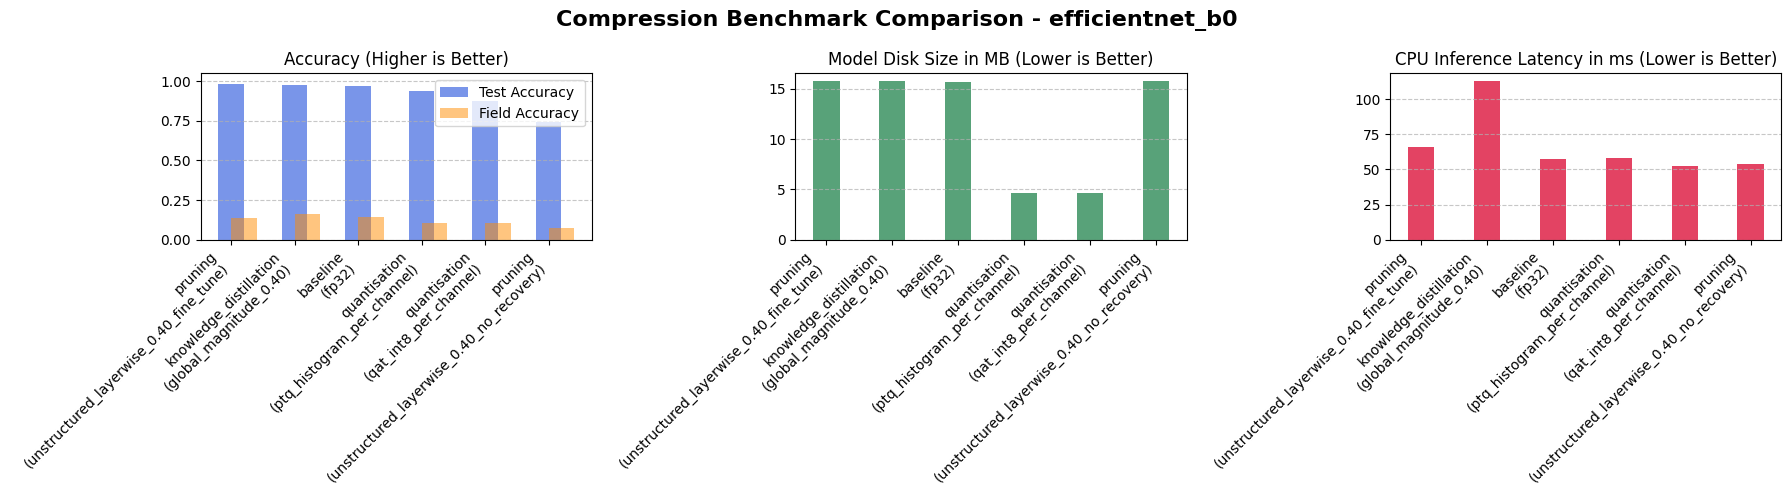

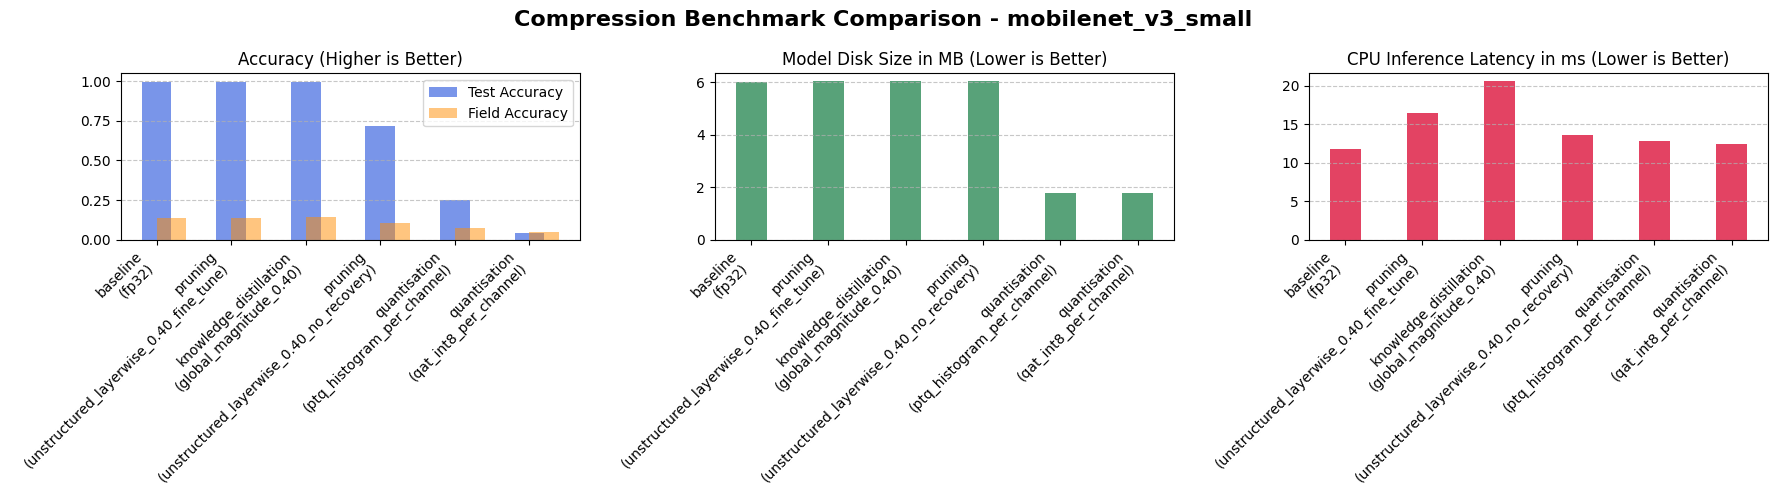

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Define the paths to our result files
baseline_path = RESULTS_DIR / 'aligned_baselines.csv'
pruning_path = RESULTS_DIR / 'aligned_pruning_results_partial.csv'
quant_path = RESULTS_DIR / 'aligned_quantisation_results_partial.csv'

# Load and concatenate whatever results are currently present
dfs = []
if baseline_path.exists():
    dfs.append(pd.read_csv(baseline_path))
if pruning_path.exists():
    dfs.append(pd.read_csv(pruning_path))
if quant_path.exists():
    dfs.append(pd.read_csv(quant_path))

if not dfs:
    print("No CSV files found yet to visualize!")
else:
    df_all = pd.concat(dfs, ignore_index=True, sort=False)

    # Pick a few key representative methods to compare per architecture
    # We'll filter for key variants to avoid over-crowding the plot
    df_subset = df_all[
        df_all['variant'].isin([
            'fp32',
            'unstructured_layerwise_0.40_no_recovery_partial',
            'unstructured_layerwise_0.40_fine_tune_partial',
            'global_magnitude_0.40_partial', # KD branch
            'ptq_histogram_per_channel_partial',
            'qat_int8_per_channel_partial'
        ])
    ].copy()

    # Create a nice label combining method + variant
    df_subset['label'] = df_subset['method'] + '\n(' + df_subset['variant'].str.replace('_partial', '') + ')'

    # Plot separately for each architecture
    for arch in df_subset['architecture'].unique():
        arch_df = df_subset[df_subset['architecture'] == arch].sort_values(by='test_accuracy', ascending=False)

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        fig.suptitle(f"Compression Benchmark Comparison - {arch}", fontsize=16, fontweight='bold')

        x_indices = range(len(arch_df))

        # 1. Test Accuracy & Field Accuracy
        axes[0].bar(x_indices, arch_df['test_accuracy'], alpha=0.7, label='Test Accuracy', color='royalblue', width=0.4, align='center')
        axes[0].bar(x_indices, arch_df['field_accuracy'], alpha=0.5, label='Field Accuracy', color='darkorange', width=0.4, align='edge')
        axes[0].set_title("Accuracy (Higher is Better)")
        axes[0].set_xticks(x_indices)
        axes[0].set_xticklabels(arch_df['label'], rotation=45, ha='right')
        axes[0].set_ylim(0, 1.05)
        axes[0].grid(axis='y', linestyle='--', alpha=0.7)
        axes[0].legend()

        # 2. Model Size (MB)
        axes[1].bar(x_indices, arch_df['model_size_mb'], color='seagreen', alpha=0.8, width=0.4)
        axes[1].set_title("Model Disk Size in MB (Lower is Better)")
        axes[1].set_xticks(x_indices)
        axes[1].set_xticklabels(arch_df['label'], rotation=45, ha='right')
        axes[1].grid(axis='y', linestyle='--', alpha=0.7)

        # 3. CPU Latency (ms)
        axes[2].bar(x_indices, arch_df['cpu_latency_mean_ms'], color='crimson', alpha=0.8, width=0.4)
        axes[2].set_title("CPU Inference Latency in ms (Lower is Better)")
        axes[2].set_xticks(x_indices)
        axes[2].set_xticklabels(arch_df['label'], rotation=45, ha='right')
        axes[2].grid(axis='y', linestyle='--', alpha=0.7)

        plt.tight_layout()
        plt.show()

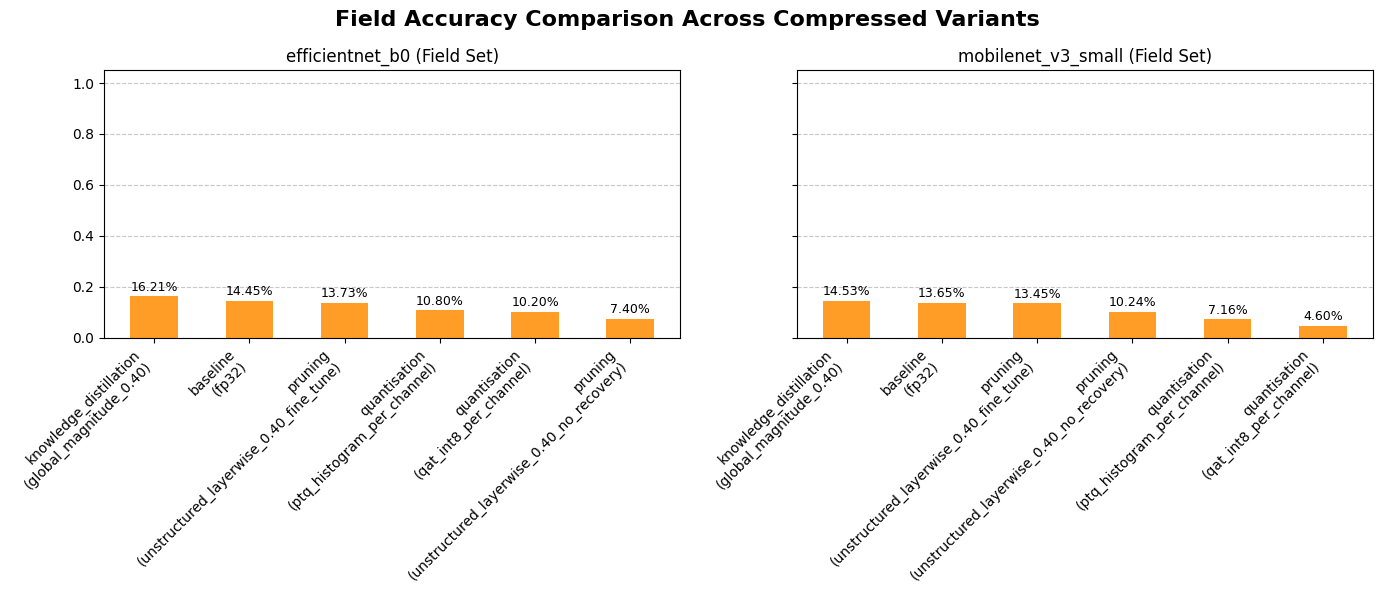

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Re-load data from our paths
dfs = []
if baseline_path.exists():
    dfs.append(pd.read_csv(baseline_path))
if pruning_path.exists():
    dfs.append(pd.read_csv(pruning_path))
if quant_path.exists():
    dfs.append(pd.read_csv(quant_path))

if not dfs:
    print("No results found yet!")
else:
    df_all = pd.concat(dfs, ignore_index=True, sort=False)

    # Filter for the key strategies we want to evaluate
    df_subset = df_all[
        df_all['variant'].isin([
            'fp32',
            'unstructured_layerwise_0.40_no_recovery_partial',
            'unstructured_layerwise_0.40_fine_tune_partial',
            'global_magnitude_0.40_partial',
            'ptq_histogram_per_channel_partial',
            'qat_int8_per_channel_partial'
        ])
    ].copy()

    df_subset['label'] = df_subset['method'] + '\n(' + df_subset['variant'].str.replace('_partial', '') + ')'

    # Create an independent visualization dedicated to Field Accuracy
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
    fig.suptitle("Field Accuracy Comparison Across Compressed Variants", fontsize=16, fontweight='bold')

    architectures = df_subset['architecture'].unique()
    for i, arch in enumerate(architectures):
        arch_df = df_subset[df_subset['architecture'] == arch].sort_values(by='field_accuracy', ascending=False)
        x_indices = range(len(arch_df))

        bars = axes[i].bar(x_indices, arch_df['field_accuracy'], color='darkorange', alpha=0.85, width=0.5)
        axes[i].set_title(f"{arch} (Field Set)", fontsize=12)
        axes[i].set_xticks(x_indices)
        axes[i].set_xticklabels(arch_df['label'], rotation=45, ha='right')
        axes[i].set_ylim(0, 1.05)
        axes[i].grid(axis='y', linestyle='--', alpha=0.7)

        # Add value labels on top of the bars
        for bar in bars:
            yval = bar.get_height()
            if not pd.isna(yval):
                axes[i].text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f"{yval:.2%}", ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
from pathlib import Path

# Define the paths to our result files
baseline_path = RESULTS_DIR / 'aligned_baselines.csv'
pruning_path = RESULTS_DIR / 'aligned_pruning_results_partial.csv'
quant_path = RESULTS_DIR / 'aligned_quantisation_results_partial.csv'

# Load and concatenate individual result files
dfs = []
if baseline_path.exists():
    dfs.append(pd.read_csv(baseline_path))
if pruning_path.exists():
    dfs.append(pd.read_csv(pruning_path))
if quant_path.exists():
    dfs.append(pd.read_csv(quant_path))

if not dfs:
    print("No results files found yet!")
else:
    df_res = pd.concat(dfs, ignore_index=True, sort=False)

    # Save combined results for future use
    df_res.to_csv(RESULTS_DIR / 'aligned_compression_results_partial.csv', index=False)
    print("Successfully consolidated and saved combined results.\n")

    print("=== Top Performing Models by Field Accuracy ===\n")
    best_rows = []
    for arch in df_res['architecture'].unique():
        arch_df = df_res[df_res['architecture'] == arch]
        # Find the row with the maximum field_accuracy
        best_row = arch_df.loc[arch_df['field_accuracy'].idxmax()]
        best_rows.append(best_row)

    summary_df = pd.DataFrame(best_rows)[[
        'architecture', 'method', 'variant',
        'field_accuracy', 'test_accuracy',
        'model_size_mb', 'cpu_latency_mean_ms'
    ]]

    display(summary_df)

Successfully consolidated and saved combined results.

=== Top Performing Models by Field Accuracy ===



,architecture,method,variant,field_accuracy,test_accuracy,model_size_mb,cpu_latency_mean_ms
17,efficientnet_b0,pruning,structured_channels_0.40_fine_tune_partial,0.167667,0.977679,15.720040,62.967355
39,mobilenet_v3_small,knowledge_distillation,global_magnitude_0.40_partial,0.145258,0.993118,6.046226,20.616005


## 10. Quantisation configuration and fixed calibration loader

Calibration uses the non-augmented transform and a fixed, seeded subset of training rows. This prevents calibration strategy comparisons from using different images.

In [ ]:
CALIBRATION_SAMPLES=min(1024,len(train_df)); rng=np.random.default_rng(SEED)
cal_idx=np.sort(rng.choice(len(train_df),size=CALIBRATION_SAMPLES,replace=False))
calibration_df=train_df.iloc[cal_idx].reset_index(drop=True)
calibration_loader=make_loader(calibration_df,eval_tf,False)
SUPPORTED=list(torch.backends.quantized.supported_engines)
QUANT_ENGINE='x86' if 'x86' in SUPPORTED else ('fbgemm' if 'fbgemm' in SUPPORTED else 'qnnpack')
torch.backends.quantized.engine=QUANT_ENGINE
example_inputs=(next(iter(calibration_loader))[0][:1].cpu(),)

def ptq_qconfig(observer='histogram',per_channel=True):
    act=(HistogramObserver if observer=='histogram' else MinMaxObserver).with_args(dtype=torch.quint8,qscheme=torch.per_tensor_affine,reduce_range=False)
    wt=(PerChannelMinMaxObserver.with_args(dtype=torch.qint8,qscheme=torch.per_channel_symmetric,ch_axis=0) if per_channel
        else MinMaxObserver.with_args(dtype=torch.qint8,qscheme=torch.per_tensor_symmetric))
    return QConfig(activation=act,weight=wt)

def quantize_ptq(model,observer='histogram',per_channel=True,mixed=False):
    checkpoint_file = RESULTS_DIR / f'interim_calib_progress_{observer}_{per_channel}_{mixed}.json'
    print(f"  [PTQ] Step 1/4: Initialising prepare_fx with engine: {QUANT_ENGINE} (observer={observer}, per_channel={per_channel}, mixed={mixed})")
    mapping=QConfigMapping().set_global(ptq_qconfig(observer,per_channel))
    if mixed: mapping=mapping.set_module_name('classifier',None)
    prepared=prepare_fx(copy.deepcopy(model).cpu().eval(),mapping,example_inputs)

    print("  [PTQ] Step 2/4: Running calibration batches on CPU...")
    with torch.inference_mode():
        total_batches = len(calibration_loader)
        for idx, (x, _) in enumerate(tqdm(calibration_loader, desc="PTQ Calibrating", leave=False)):
            prepared(x.cpu())
            # Save progress check every 10 steps to file
            if (idx + 1) % 10 == 0 or (idx + 1) == total_batches:
                print(f"    [Calibration Progress] Processed batch {idx + 1}/{total_batches}")
                progress_data = {"last_processed_batch": idx + 1, "total_batches": total_batches, "status": "calibrating"}
                try:
                    checkpoint_file.write_text(json.dumps(progress_data))
                except Exception:
                    pass

    print("  [PTQ] Step 3/4: Converting prepared model to quantised representation...")
    quantized_model = convert_fx(prepared).eval()

    # Update checkpoint file to reflect success
    try:
        checkpoint_file.write_text(json.dumps({"status": "completed"}))
    except Exception:
        pass

    print("  [PTQ] Step 4/4: Model quantisation completed successfully.")
    return quantized_model

## 11. Quantisation-aware training using the same validation metric

In [ ]:
QAT_EPOCHS=1; QAT_LR=1e-5

def qat_qconfig():
    return QConfig(
      activation=FakeQuantize.with_args(observer=MovingAverageMinMaxObserver,dtype=torch.quint8,qscheme=torch.per_tensor_affine,reduce_range=False),
      weight=FakeQuantize.with_args(observer=MovingAveragePerChannelMinMaxObserver,dtype=torch.qint8,qscheme=torch.per_channel_symmetric,ch_axis=0))

def quantize_qat(model):
    checkpoint_file = RESULTS_DIR / 'interim_qat_progress.json'
    print("  [QAT] Step 1/4: Initialising QAT configuration and preparing FX graph...")
    prepared=prepare_qat_fx(copy.deepcopy(model).cpu().train(),QConfigMapping().set_global(qat_qconfig()),example_inputs).to(device)

    print("  [QAT] Step 2/4: Optimising trainable parameters over training epochs...")
    trainable_params = [p for p in prepared.parameters() if p.requires_grad]
    opt=optim.AdamW(trainable_params,lr=QAT_LR,weight_decay=1e-4); best=copy.deepcopy(prepared.state_dict()); score=-1

    for epoch in range(QAT_EPOCHS):
        prepared.train()
        total_batches = len(train_loader)
        for idx, (x, y) in enumerate(tqdm(train_loader, desc=f'QAT {epoch+1}/{QAT_EPOCHS}', leave=False)):
            x,y=x.to(device),y.to(device); opt.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                loss=F.cross_entropy(prepared(x),y)
            loss.backward(); opt.step()

            # Save intermediate training batch progress to local JSON
            if (idx + 1) % 50 == 0 or (idx + 1) == total_batches:
                print(f"    [QAT Progress] Epoch {epoch+1}/{QAT_EPOCHS} - Batch {idx+1}/{total_batches} - Loss: {loss.item():.4f}")
                progress_data = {"epoch": epoch + 1, "batch": idx + 1, "loss": loss.item(), "status": "training"}
                try:
                    checkpoint_file.write_text(json.dumps(progress_data))
                except Exception:
                    pass

        print("  [QAT] Step 3/4: Disabling observers and evaluating on validation split...")
        val=evaluate_split(prepared,val_loader,device)
        if val['macro_f1']>score:
            score=val['macro_f1']
            best=copy.deepcopy(prepared.state_dict())
        if epoch==QAT_EPOCHS-1:
            prepared.apply(disable_observer)

    prepared.load_state_dict(best)
    print("  [QAT] Step 4/4: Finalising conversion to fully-quantised representation...")
    quantized_model = convert_fx(prepared.cpu().eval()).eval()

    try:
        checkpoint_file.write_text(json.dumps({"status": "completed"}))
    except Exception:
        pass

    print("  [QAT] QAT execution completed successfully.")
    return quantized_model

## 12. Run aligned quantisation experiments

## only run below if want to start over and delete checkpoints

In [ ]:
# # --- Script to delete existing quantisation checkpoint JSON and CSV files ---
# import glob
# from pathlib import Path

# # 1. Locate and delete interim calibration/QAT json checkpoints
# json_checkpoints = list(RESULTS_DIR.glob("interim_*.json"))
# if not json_checkpoints:
#     print(f"No existing quantization checkpoint JSON files found in {RESULTS_DIR}.")
# else:
#     print(f"Found {len(json_checkpoints)} quantization checkpoint JSON files to delete:")
#     for filepath in json_checkpoints:
#         try:
#             filepath.unlink()
#             print(f"  Successfully deleted: {filepath.name}")
#         except Exception as e:
#             print(f"  Failed to delete {filepath.name}: {e}")

# # 2. Locate and delete the quantization output CSV files
# quant_csv_files = [
#     RESULTS_DIR / 'aligned_quantisation_results_partial.csv',
#     # also check for any backup files if present
#     *list(RESULTS_DIR.glob("aligned_quantisation_results_partial_backup_*.csv"))
# ]

# print("\nChecking for quantization CSV outputs to delete:")
# deleted_csv_count = 0
# for filepath in quant_csv_files:
#     if filepath.exists():
#         try:
#             filepath.unlink()
#             print(f"  Successfully deleted: {filepath.name}")
#             deleted_csv_count += 1
#         except Exception as e:
#             print(f"  Failed to delete {filepath.name}: {e}")

# if deleted_csv_count == 0:
#     print("  No quantization CSV output files found to delete.")

# print("\nCleanup complete.")

No existing quantization checkpoint JSON files found in /content/drive/Shareddrives/COS 801 Group 6/results/aligned_compression_partial.

Checking for quantization CSV outputs to delete:
  Successfully deleted: aligned_quantisation_results_partial.csv

Cleanup complete.


In [ ]:
import gc
import os
import pandas as pd
from datetime import datetime

quant_results_path = RESULTS_DIR / 'aligned_quantisation_results_partial.csv'

# --- FORCE RESET CONTROL ---
# Change this to True to archive existing CSV results and force a complete rerun
FORCE_RERUN = False

if FORCE_RERUN and quant_results_path.exists():
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    backup_path = quant_results_path.with_name(f"aligned_quantisation_results_partial_backup_{timestamp}.csv")
    quant_results_path.rename(backup_path)
    print(f"[Reset] Archived old results to: {backup_path.name}")

# 1. Load existing progress if available
if quant_results_path.exists():
    try:
        quant_rows = pd.read_csv(quant_results_path).to_dict('records')
        print(f"Loaded {len(quant_rows)} previously completed quantisation records.")
    except Exception:
        quant_rows = []
else:
    quant_rows = []

def quant_record_exists(arch, variant):
    return any(r['architecture'] == arch and r['variant'] == variant for r in quant_rows)

for arch, baseline in BASELINES.items():
    print(f"\n=== Starting/Resuming Quantisation for {arch} ===")

    # 2. Post-Training Quantisation (PTQ) Specs
    specs = [
        ('ptq_minmax_per_channel_partial', 'minmax', True, False),
        ('ptq_histogram_per_channel_partial', 'histogram', True, False),
        ('ptq_histogram_per_tensor_partial', 'histogram', False, False),
        ('mixed_int8_fp32_partial', 'histogram', True, True)
    ]
    for name, obs, pc, mixed in specs:
        if quant_record_exists(arch, name):
            print(f"  [PTQ] Skipping {name} (record already exists in CSV).")
            continue

        q = quantize_ptq(baseline, obs, pc, mixed)
        row = evaluate_model(q, arch, 'quantisation', name, {'quant_engine': QUANT_ENGINE, 'calibration_samples': CALIBRATION_SAMPLES})
        quant_rows.append(row)

        # Save interim progress to disk immediately
        pd.DataFrame(quant_rows).to_csv(quant_results_path, index=False)

        # Free memory immediately
        del q
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # 3. Quantisation-Aware Training (QAT)
    qat_name = 'qat_int8_per_channel_partial'
    if quant_record_exists(arch, qat_name):
        print(f"  [QAT] Skipping {qat_name} (record already exists in CSV).")
    else:
        q = quantize_qat(baseline)
        row = evaluate_model(q, arch, 'quantisation', qat_name, {'quant_engine': QUANT_ENGINE})
        quant_rows.append(row)

        # Save interim progress to disk immediately
        pd.DataFrame(quant_rows).to_csv(quant_results_path, index=False)

        # Free memory immediately
        del q
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# Final summary saving
quant_df = pd.DataFrame(quant_rows)
quant_df.to_csv(quant_results_path, index=False)

print(f"\n[Success] Quantisation experiments completed/loaded. Total saved records: {len(quant_df)}.")
display(quant_df[['architecture', 'variant', 'test_accuracy', 'field_accuracy', 'model_size_mb']])


=== Starting/Resuming Quantisation for efficientnet_b0 ===
  [PTQ] Step 1/4: Initialising prepare_fx with engine: x86 (observer=minmax, per_channel=True, mixed=False)


/tmp/ipykernel_142893/1880146058.py:21: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared=prepare_fx(copy.deepcopy(model).cpu().eval(),mapping,example_inputs)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/fx/utils.py:994: UserWarning: QConfig must specify a FixedQParamsObserver or a FixedQParamsFakeQuantize for fixed qparams ops, ignoring QConfig(act

  [PTQ] Step 2/4: Running calibration batches on CPU...


PTQ Calibrating:   0%|          | 0/32 [00:00<?, ?it/s]

    [Calibration Progress] Processed batch 10/32
    [Calibration Progress] Processed batch 20/32
    [Calibration Progress] Processed batch 30/32
    [Calibration Progress] Processed batch 32/32
  [PTQ] Step 3/4: Converting prepared model to quantised representation...


/tmp/ipykernel_142893/1880146058.py:38: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = convert_fx(prepared).eval()


... (86 outputs left out)

  0%|          | 0/168 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]


[Success] Quantisation experiments completed/loaded. Total saved records: 10.


,architecture,variant,test_accuracy,field_accuracy,model_size_mb
0,efficientnet_b0,ptq_minmax_per_channel_partial,0.407552,0.070428,4.616973
1,efficientnet_b0,ptq_histogram_per_channel_partial,0.941220,0.108043,4.626019
2,efficientnet_b0,ptq_histogram_per_tensor_partial,0.016183,0.026010,4.104800
3,efficientnet_b0,mixed_int8_fp32_partial,0.941406,0.109644,4.705136
4,efficientnet_b0,qat_int8_per_channel_partial,0.874442,0.102041,4.615642
5,mobilenet_v3_small,ptq_minmax_per_channel_partial,0.215960,0.071228,1.790431
6,mobilenet_v3_small,ptq_histogram_per_channel_partial,0.249814,0.071629,1.793284
7,mobilenet_v3_small,ptq_histogram_per_tensor_partial,0.059338,0.042017,1.607795
8,mobilenet_v3_small,mixed_int8_fp32_partial,0.256510,0.072029,3.528167
9,mobilenet_v3_small,qat_int8_per_channel_partial,0.041667,0.046018,1.785884


## 13. Combine only aligned results

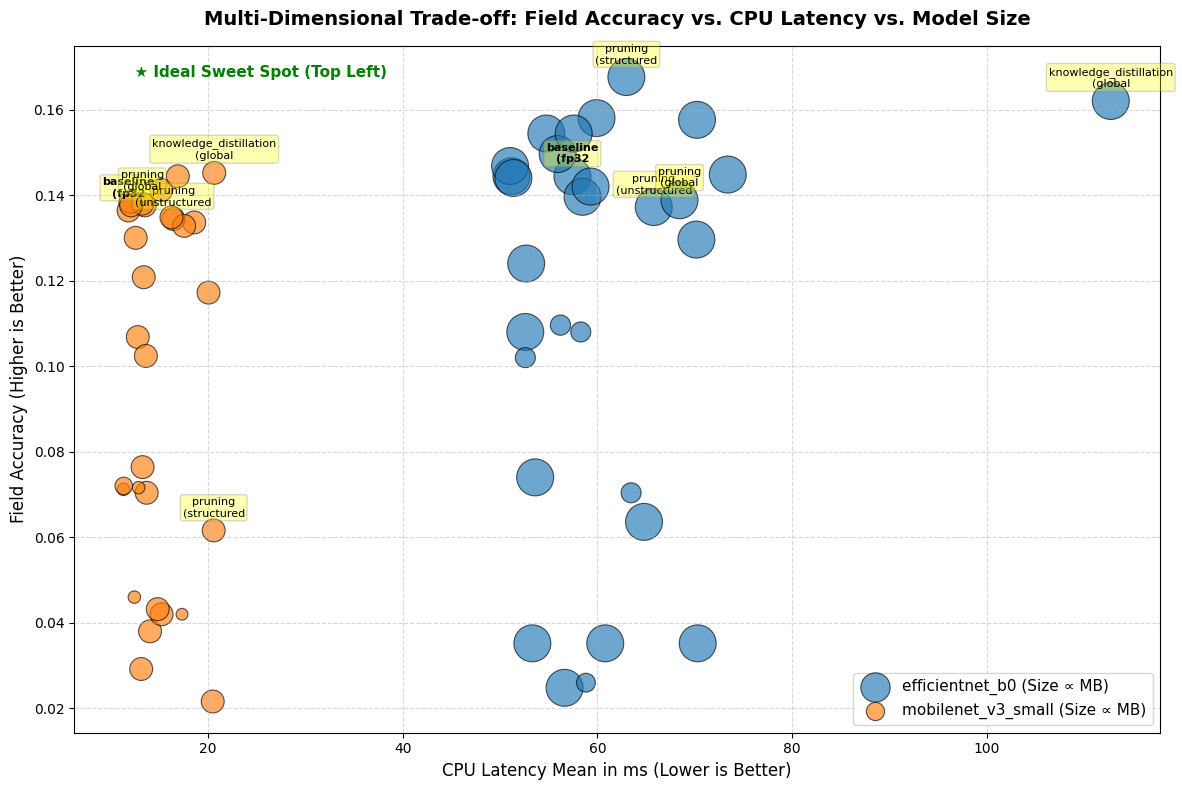

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Re-load consolidated results
results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_plot = pd.read_csv(results_path)

    # Drop any rows with missing latency or accuracy values to clean up the plot
    df_plot = df_plot.dropna(subset=['field_accuracy', 'cpu_latency_mean_ms', 'model_size_mb'])

    plt.figure(figsize=(12, 8))

    # Distinct markers/colors per architecture
    colors = {'efficientnet_b0': '#1f77b4', 'mobilenet_v3_small': '#ff7f0e'}

    for arch in df_plot['architecture'].unique():
        sub_df = df_plot[df_plot['architecture'] == arch]

        # Size of bubble is proportional to model size (scaled up for visualization visibility)
        sizes = sub_df['model_size_mb'] * 45

        sc = plt.scatter(
            sub_df['cpu_latency_mean_ms'],
            sub_df['field_accuracy'],
            s=sizes,
            c=colors.get(arch, 'gray'),
            label=f"{arch} (Size ∝ MB)",
            alpha=0.65,
            edgecolors='black',
            linewidths=0.8
        )

        # Label key top-performing or interesting variants to avoid crowding
        for _, row in sub_df.iterrows():
            is_baseline = row['method'] == 'baseline'
            is_best_prune = 'fine_tune' in str(row['variant']) and '0.40' in str(row['variant'])
            is_kd = 'global_magnitude_0.40_partial' in str(row['variant'])

            if is_baseline or is_best_prune or is_kd:
                label_text = f"{row['method']}\n({row['variant'].split('_')[0] if not is_baseline else 'fp32'}"
                plt.annotate(
                    label_text,
                    (row['cpu_latency_mean_ms'], row['field_accuracy']),
                    textcoords="offset points",
                    xytext=(0, 10),
                    ha='center',
                    fontsize=8,
                    fontweight='bold' if is_baseline else 'normal',
                    bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.3, ec="gray")
                )

    plt.title("Multi-Dimensional Trade-off: Field Accuracy vs. CPU Latency vs. Model Size", fontsize=14, fontweight='bold', pad=15)
    plt.ylabel("Field Accuracy (Higher is Better)", fontsize=12)
    plt.xlabel("CPU Latency Mean in ms (Lower is Better)", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='lower right', fontsize=11)

    # Add a visual indicator of the optimal zone
    plt.text(df_plot['cpu_latency_mean_ms'].min(), df_plot['field_accuracy'].max(), "  ★ Ideal Sweet Spot (Top Left)", color='green', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.show()
else:
    print("Consolidated results CSV not found! Please run the preceding consolidation cell first.")

/tmp/ipykernel_1272/457790459.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(arch_df['variant'], rotation=45, ha='right', fontsize=8)


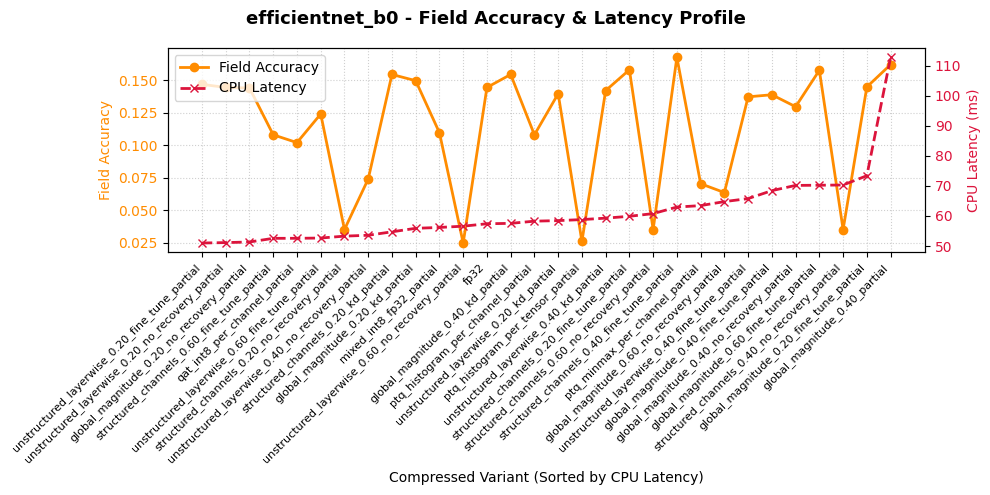

/tmp/ipykernel_1272/457790459.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(arch_df['variant'], rotation=45, ha='right', fontsize=8)


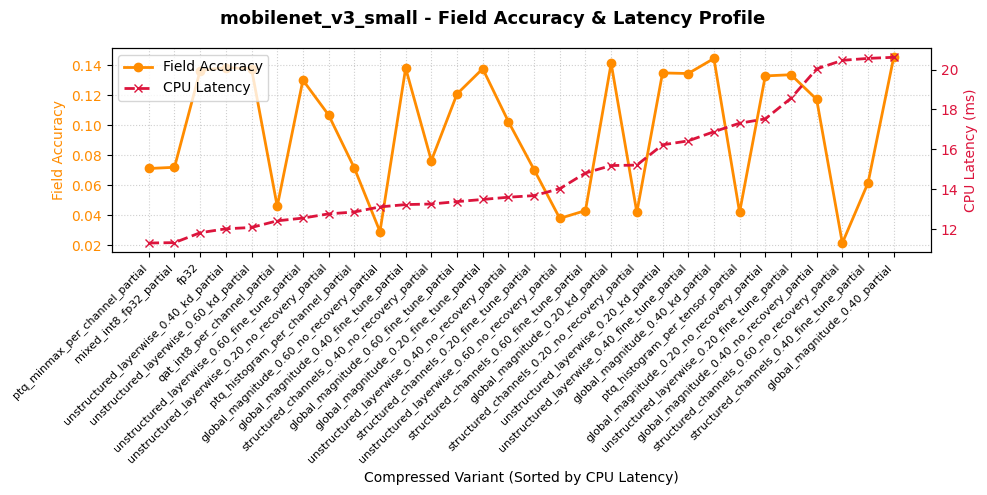

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_results = pd.read_csv(results_path)
    df_clean = df_results.dropna(subset=['field_accuracy', 'cpu_latency_mean_ms']).copy()

    # Plot separately for each architecture to keep trade-offs clear
    for arch in df_clean['architecture'].unique():
        arch_df = df_clean[df_clean['architecture'] == arch].copy()

        # Sort values by latency to produce logical progression line charts
        arch_df = arch_df.sort_values(by='cpu_latency_mean_ms')

        fig, ax1 = plt.subplots(figsize=(10, 5))
        fig.suptitle(f"{arch} - Field Accuracy & Latency Profile", fontsize=13, fontweight='bold')

        # Plot Field Accuracy (Left Axis)
        color = 'darkorange'
        ax1.set_xlabel('Compressed Variant (Sorted by CPU Latency)', fontsize=10)
        ax1.set_ylabel('Field Accuracy', color=color, fontsize=10)
        line1 = ax1.plot(arch_df['variant'], arch_df['field_accuracy'], color=color, marker='o', linewidth=2, label='Field Accuracy')
        ax1.tick_params(axis='y', labelcolor=color)
        ax1.set_xticklabels(arch_df['variant'], rotation=45, ha='right', fontsize=8)
        ax1.grid(True, linestyle=':', alpha=0.6)

        # Instantiate a second axes that shares the same x-axis for Latency
        ax2 = ax1.twinx()
        color = 'crimson'
        ax2.set_ylabel('CPU Latency (ms)', color=color, fontsize=10)
        line2 = ax2.plot(arch_df['variant'], arch_df['cpu_latency_mean_ms'], color=color, marker='x', linestyle='--', linewidth=2, label='CPU Latency')
        ax2.tick_params(axis='y', labelcolor=color)

        # Add a combined legend
        lines = line1 + line2
        labels = [l.get_label() for l in lines]
        ax1.legend(lines, labels, loc='upper left')

        plt.tight_layout()
        plt.show()
else:
    print("Consolidated results CSV not found! Please run the consolidation cells first.")

In [ ]:
import pandas as pd
from IPython.display import display, HTML

results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_results = pd.read_csv(results_path)
    # Filter to only efficientnet_b0
    df_eff = df_results[df_results['architecture'] == 'efficientnet_b0'].copy()

    # --- Define System-Fitness Index Weights & Normalizers ---
    max_lat = df_eff['cpu_latency_mean_ms'].max()
    max_size = df_eff['model_size_mb'].max()

    # Fitness function
    def calc_fitness(row, w_acc, w_lat, w_size):
        # Normalize latency and size relative to max in the subset (lower is better, so we subtract)
        acc_score = row['field_accuracy']
        lat_score = row['cpu_latency_mean_ms'] / max_lat if max_lat > 0 else 1.0
        size_score = row['model_size_mb'] / max_size if max_size > 0 else 1.0
        return w_acc * acc_score - w_lat * lat_score - w_size * size_score

    # Calculate scores for different scenarios
    df_eff['Fitness_Server'] = df_eff.apply(lambda r: calc_fitness(r, 0.8, 0.1, 0.1), axis=1)
    df_eff['Fitness_Mobile'] = df_eff.apply(lambda r: calc_fitness(r, 0.3, 0.5, 0.2), axis=1)
    df_eff['Fitness_IoT'] = df_eff.apply(lambda r: calc_fitness(r, 0.2, 0.3, 0.5), axis=1)

    cols_to_show = [
        'architecture', 'method', 'variant', 'field_accuracy', 'test_accuracy',
        'model_size_mb', 'cpu_latency_mean_ms', 'Fitness_Server', 'Fitness_Mobile', 'Fitness_IoT'
    ]

    # 1. Pruning & KD Results Table (Sorted by Field Accuracy)
    pruning_df = df_eff[df_eff['method'].isin(['baseline', 'pruning', 'knowledge_distillation'])].copy()
    pruning_sorted = pruning_df.sort_values(by='field_accuracy', ascending=False)[cols_to_show].reset_index(drop=True)

    print("=== EfficientNet-B0: Pruning & KD Results Table with System-Fitness Index ===")
    display(pruning_sorted)

    # 2. Quantisation Results Table (Sorted by Field Accuracy)
    quant_df = df_eff[df_eff['method'].isin(['baseline', 'quantisation'])].copy()
    quant_sorted = quant_df.sort_values(by='field_accuracy', ascending=False)[cols_to_show].reset_index(drop=True)

    print("\n=== EfficientNet-B0: Quantisation Results Table with System-Fitness Index ===")
    display(quant_sorted)
else:
    print("Consolidated results CSV not found! Please run the consolidation cells first.")

=== EfficientNet-B0: Pruning & KD Results Table with System-Fitness Index ===


,architecture,method,variant,field_accuracy,test_accuracy,model_size_mb,cpu_latency_mean_ms,Fitness_Server,Fitness_Mobile,Fitness_IoT
0,efficientnet_b0,pruning,structured_channels_0.40_fine_tune_partial,0.167667,0.977679,15.720040,62.967355,-0.021583,-0.428687,-0.633349
1,efficientnet_b0,knowledge_distillation,global_magnitude_0.40_partial,0.162065,0.976749,15.720799,112.741441,-0.070219,-0.651122,-0.766941
2,efficientnet_b0,pruning,structured_channels_0.20_fine_tune_partial,0.158063,0.987909,15.720040,59.901576,-0.026547,-0.417972,-0.627112
3,efficientnet_b0,pruning,global_magnitude_0.60_fine_tune_partial,0.157663,0.971912,15.718871,70.227479,-0.036019,-0.463872,-0.654632
4,efficientnet_b0,knowledge_distillation,structured_channels_0.20_kd_partial,0.154462,0.984189,15.740106,54.743164,-0.024980,-0.396430,-0.614744
5,efficientnet_b0,knowledge_distillation,global_magnitude_0.40_kd_partial,0.154462,0.977121,15.738570,57.553876,-0.027464,-0.408876,-0.622174
6,efficientnet_b0,knowledge_distillation,global_magnitude_0.20_kd_partial,0.149660,0.978609,15.738570,55.908586,-0.029846,-0.403020,-0.618756
7,efficientnet_b0,pruning,unstructured_layerwise_0.20_fine_tune_partial,0.146859,0.983817,15.721148,51.015020,-0.027635,-0.381936,-0.605742
8,efficientnet_b0,pruning,global_magnitude_0.20_fine_tune_partial,0.144858,0.982515,15.718871,73.385749,-0.049064,-0.481720,-0.665597
9,efficientnet_b0,baseline,fp32,0.144458,0.970052,15.702365,57.419464,-0.035118,-0.410821,-0.622667



=== EfficientNet-B0: Quantisation Results Table with System-Fitness Index ===


,architecture,method,variant,field_accuracy,test_accuracy,model_size_mb,cpu_latency_mean_ms,Fitness_Server,Fitness_Mobile,Fitness_IoT
0,efficientnet_b0,baseline,fp32,0.144458,0.970052,15.702365,57.419464,-0.035118,-0.410821,-0.622667
1,efficientnet_b0,quantisation,mixed_int8_fp32_partial,0.109644,0.941406,4.705136,56.195117,0.007980,-0.276109,-0.277057
2,efficientnet_b0,quantisation,ptq_histogram_per_channel_partial,0.108043,0.941220,4.626019,58.281470,0.005352,-0.284837,-0.280416
3,efficientnet_b0,quantisation,qat_int8_per_channel_partial,0.102041,0.874442,4.615642,52.585993,0.005668,-0.261247,-0.266132
4,efficientnet_b0,quantisation,ptq_minmax_per_channel_partial,0.070428,0.407552,4.616973,63.453249,-0.029270,-0.318943,-0.301414
5,efficientnet_b0,quantisation,ptq_histogram_per_tensor_partial,0.026010,0.016183,4.104800,58.808108,-0.057430,-0.305160,-0.281668


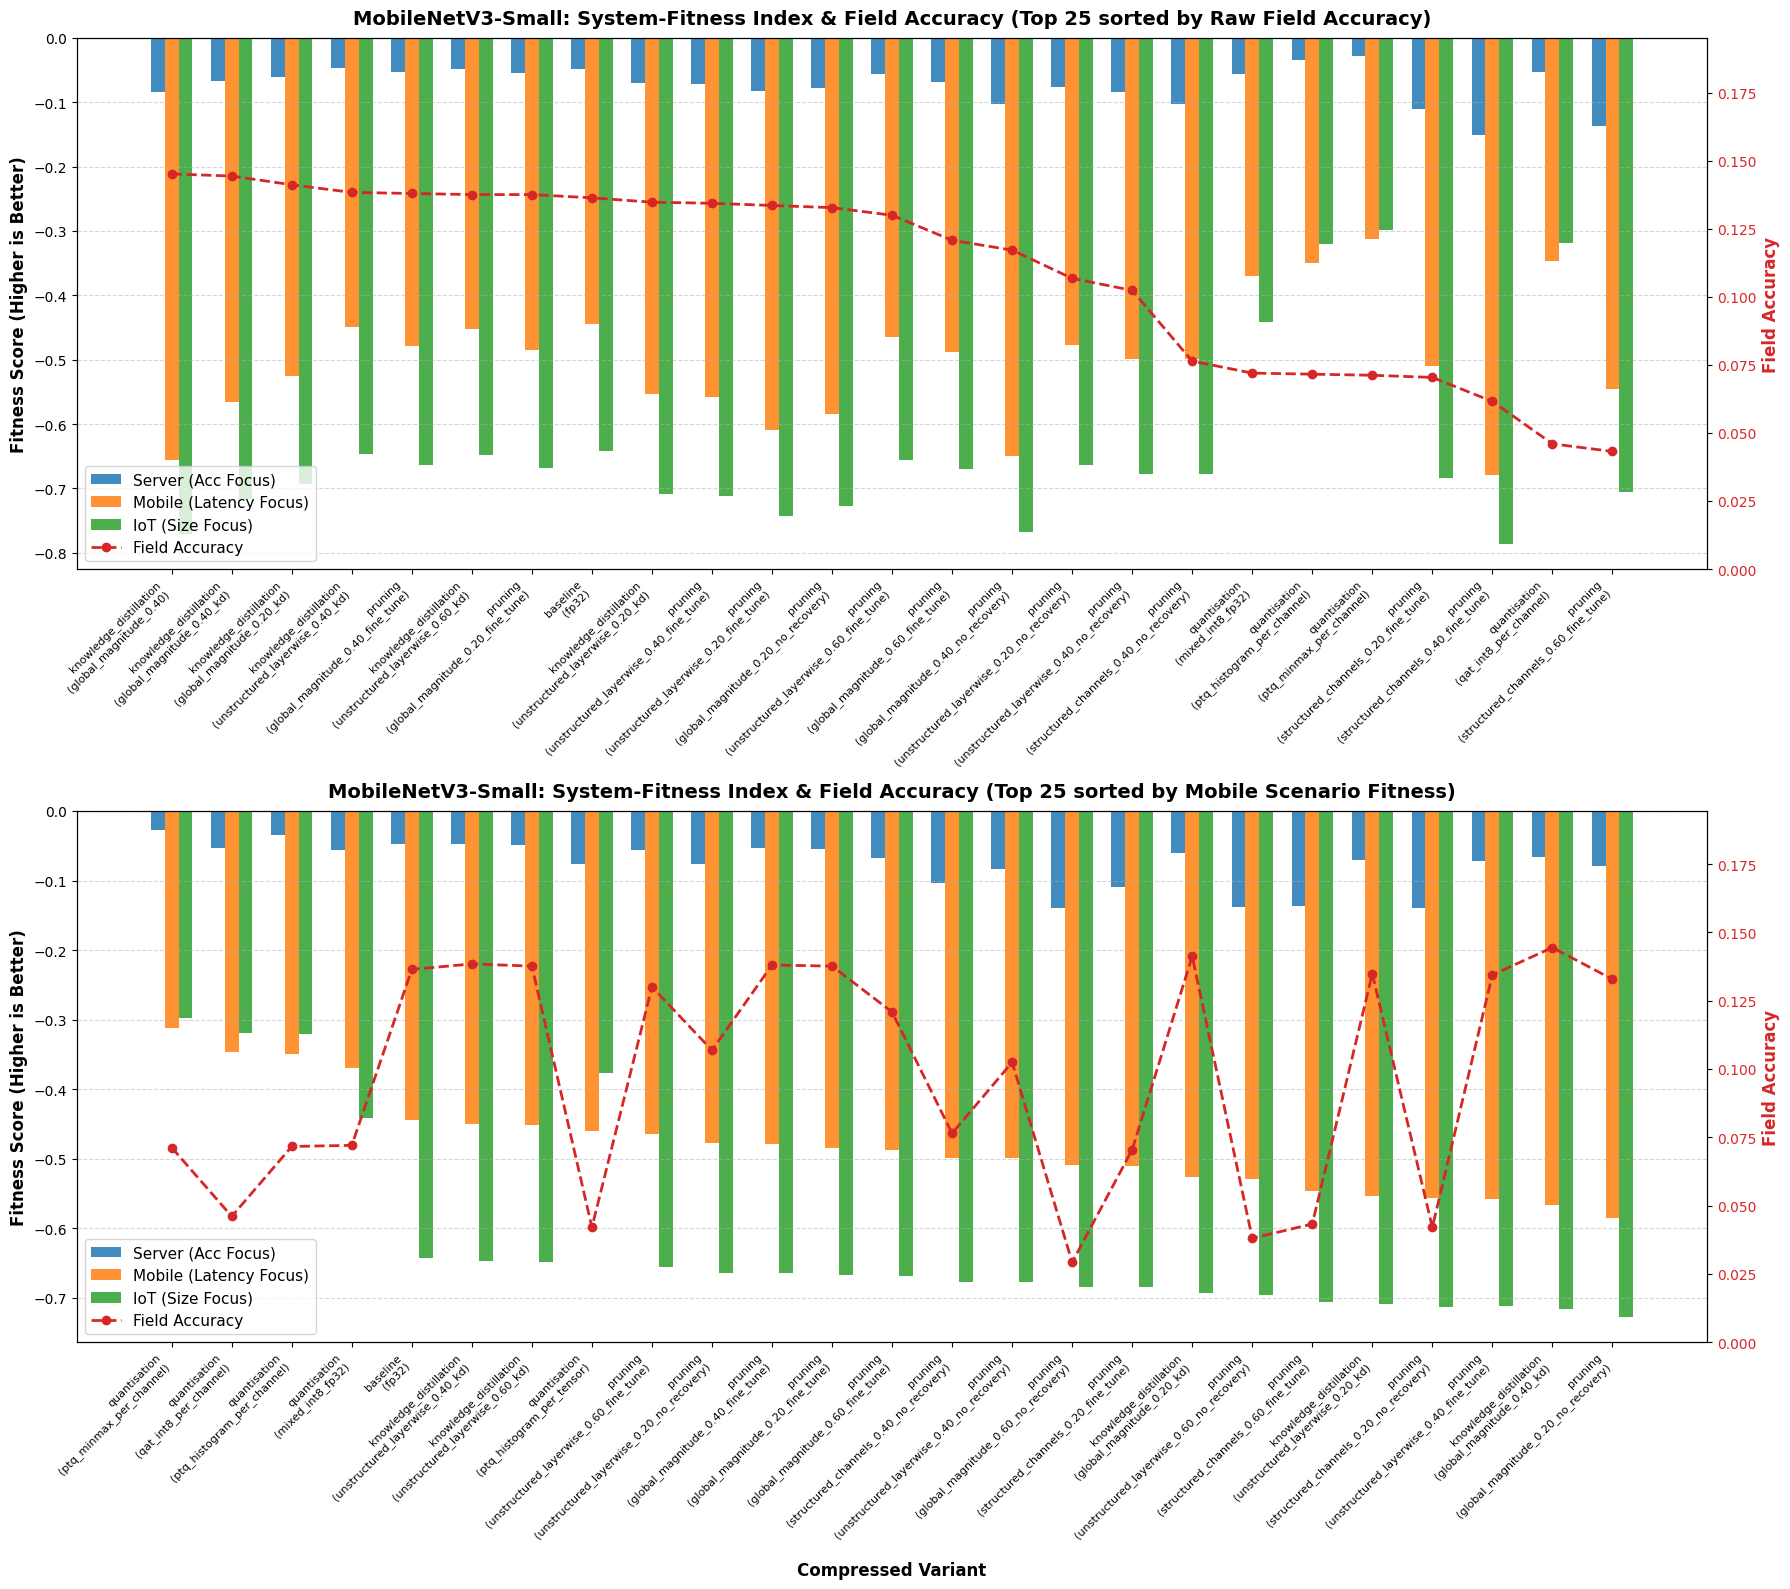

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_results = pd.read_csv(results_path)
    df_mob = df_results[df_results['architecture'] == 'mobilenet_v3_small'].copy()

    # Define normalization limits based on MobileNet dataset maximums
    max_lat = df_mob['cpu_latency_mean_ms'].max()
    max_size = df_mob['model_size_mb'].max()

    # Calculate scores
    def calc_fitness(row, w_acc, w_lat, w_size):
        acc_score = row['field_accuracy']
        lat_score = row['cpu_latency_mean_ms'] / max_lat if max_lat > 0 else 1.0
        size_score = row['model_size_mb'] / max_size if max_size > 0 else 1.0
        return w_acc * acc_score - w_lat * lat_score - w_size * size_score

    df_mob['Server Scenario'] = df_mob.apply(lambda r: calc_fitness(r, 0.8, 0.1, 0.1), axis=1)
    df_mob['Mobile Scenario'] = df_mob.apply(lambda r: calc_fitness(r, 0.3, 0.5, 0.2), axis=1)
    df_mob['IoT Scenario'] = df_mob.apply(lambda r: calc_fitness(r, 0.2, 0.3, 0.5), axis=1)

    # --- Graph 1: Sorted by Pure Field Accuracy ---
    df_plot_acc = df_mob.sort_values(by=['field_accuracy', 'cpu_latency_mean_ms'], ascending=[False, True]).head(25).copy()
    df_plot_acc['label'] = df_plot_acc['method'] + '\n(' + df_plot_acc['variant'].str.replace('_partial', '') + ')'

    fig, (ax_acc1, ax_mob1) = plt.subplots(2, 1, figsize=(18, 16))

    x = np.arange(len(df_plot_acc))
    width = 0.23

    # Plot 1 (Accuracy Sorted) Primary Y-axis
    ax_acc1.bar(x - width, df_plot_acc['Server Scenario'], width, label='Server (Acc Focus)', color='#1f77b4', alpha=0.85)
    ax_acc1.bar(x, df_plot_acc['Mobile Scenario'], width, label='Mobile (Latency Focus)', color='#ff7f0e', alpha=0.85)
    ax_acc1.bar(x + width, df_plot_acc['IoT Scenario'], width, label='IoT (Size Focus)', color='#2ca02c', alpha=0.85)
    ax_acc1.set_ylabel('Fitness Score (Higher is Better)', fontsize=12, fontweight='bold')
    ax_acc1.set_title('MobileNetV3-Small: System-Fitness Index & Field Accuracy (Top 25 sorted by Raw Field Accuracy)', fontsize=14, fontweight='bold', pad=10)
    ax_acc1.set_xticks(x)
    ax_acc1.set_xticklabels(df_plot_acc['label'], rotation=45, ha='right', fontsize=8)
    ax_acc1.grid(axis='y', linestyle='--', alpha=0.5)

    # Plot 1 Secondary Y-axis
    ax_acc2 = ax_acc1.twinx()
    ax_acc2.plot(x, df_plot_acc['field_accuracy'], color='#d62728', marker='o', markersize=6, linewidth=2.0, linestyle='--', label='Field Accuracy')
    ax_acc2.set_ylabel('Field Accuracy', color='#d62728', fontsize=12, fontweight='bold')
    ax_acc2.tick_params(axis='y', labelcolor='#d62728')
    min_acc = max(0.0, df_plot_acc['field_accuracy'].min() - 0.05)
    max_acc = min(1.0, df_plot_acc['field_accuracy'].max() + 0.05)
    ax_acc2.set_ylim(min_acc, max_acc)

    lines, labels = ax_acc1.get_legend_handles_labels()
    lines2, labels2 = ax_acc2.get_legend_handles_labels()
    ax_acc1.legend(lines + lines2, labels + labels2, loc='lower left', fontsize=11)

    # --- Graph 2: Sorted by Mobile Scenario Fitness ---
    df_plot_mob = df_mob.sort_values(by=['Mobile Scenario', 'field_accuracy'], ascending=[False, False]).head(25).copy()
    df_plot_mob['label'] = df_plot_mob['method'] + '\n(' + df_plot_mob['variant'].str.replace('_partial', '') + ')'

    # Plot 2 (Mobile Sorted) Primary Y-axis
    ax_mob1.bar(x - width, df_plot_mob['Server Scenario'], width, label='Server (Acc Focus)', color='#1f77b4', alpha=0.85)
    ax_mob1.bar(x, df_plot_mob['Mobile Scenario'], width, label='Mobile (Latency Focus)', color='#ff7f0e', alpha=0.85)
    ax_mob1.bar(x + width, df_plot_mob['IoT Scenario'], width, label='IoT (Size Focus)', color='#2ca02c', alpha=0.85)
    ax_mob1.set_ylabel('Fitness Score (Higher is Better)', fontsize=12, fontweight='bold')
    ax_mob1.set_xlabel('Compressed Variant', fontsize=12, fontweight='bold', labelpad=15)
    ax_mob1.set_title('MobileNetV3-Small: System-Fitness Index & Field Accuracy (Top 25 sorted by Mobile Scenario Fitness)', fontsize=14, fontweight='bold', pad=10)
    ax_mob1.set_xticks(x)
    ax_mob1.set_xticklabels(df_plot_mob['label'], rotation=45, ha='right', fontsize=8)
    ax_mob1.grid(axis='y', linestyle='--', alpha=0.5)

    # Plot 2 Secondary Y-axis
    ax_mob2 = ax_mob1.twinx()
    ax_mob2.plot(x, df_plot_mob['field_accuracy'], color='#d62728', marker='o', markersize=6, linewidth=2.0, linestyle='--', label='Field Accuracy')
    ax_mob2.set_ylabel('Field Accuracy', color='#d62728', fontsize=12, fontweight='bold')
    ax_mob2.tick_params(axis='y', labelcolor='#d62728')
    min_acc_m = max(0.0, df_plot_mob['field_accuracy'].min() - 0.05)
    max_acc_m = min(1.0, df_plot_mob['field_accuracy'].max() + 0.05)
    ax_mob2.set_ylim(min_acc_m, max_acc_m)

    lines_m, labels_m = ax_mob1.get_legend_handles_labels()
    lines2_m, labels2_m = ax_mob2.get_legend_handles_labels()
    ax_mob1.legend(lines_m + lines2_m, labels_m + labels2_m, loc='lower left', fontsize=11)

    plt.tight_layout()
    plt.show()
else:
    print("Consolidated results CSV not found!")

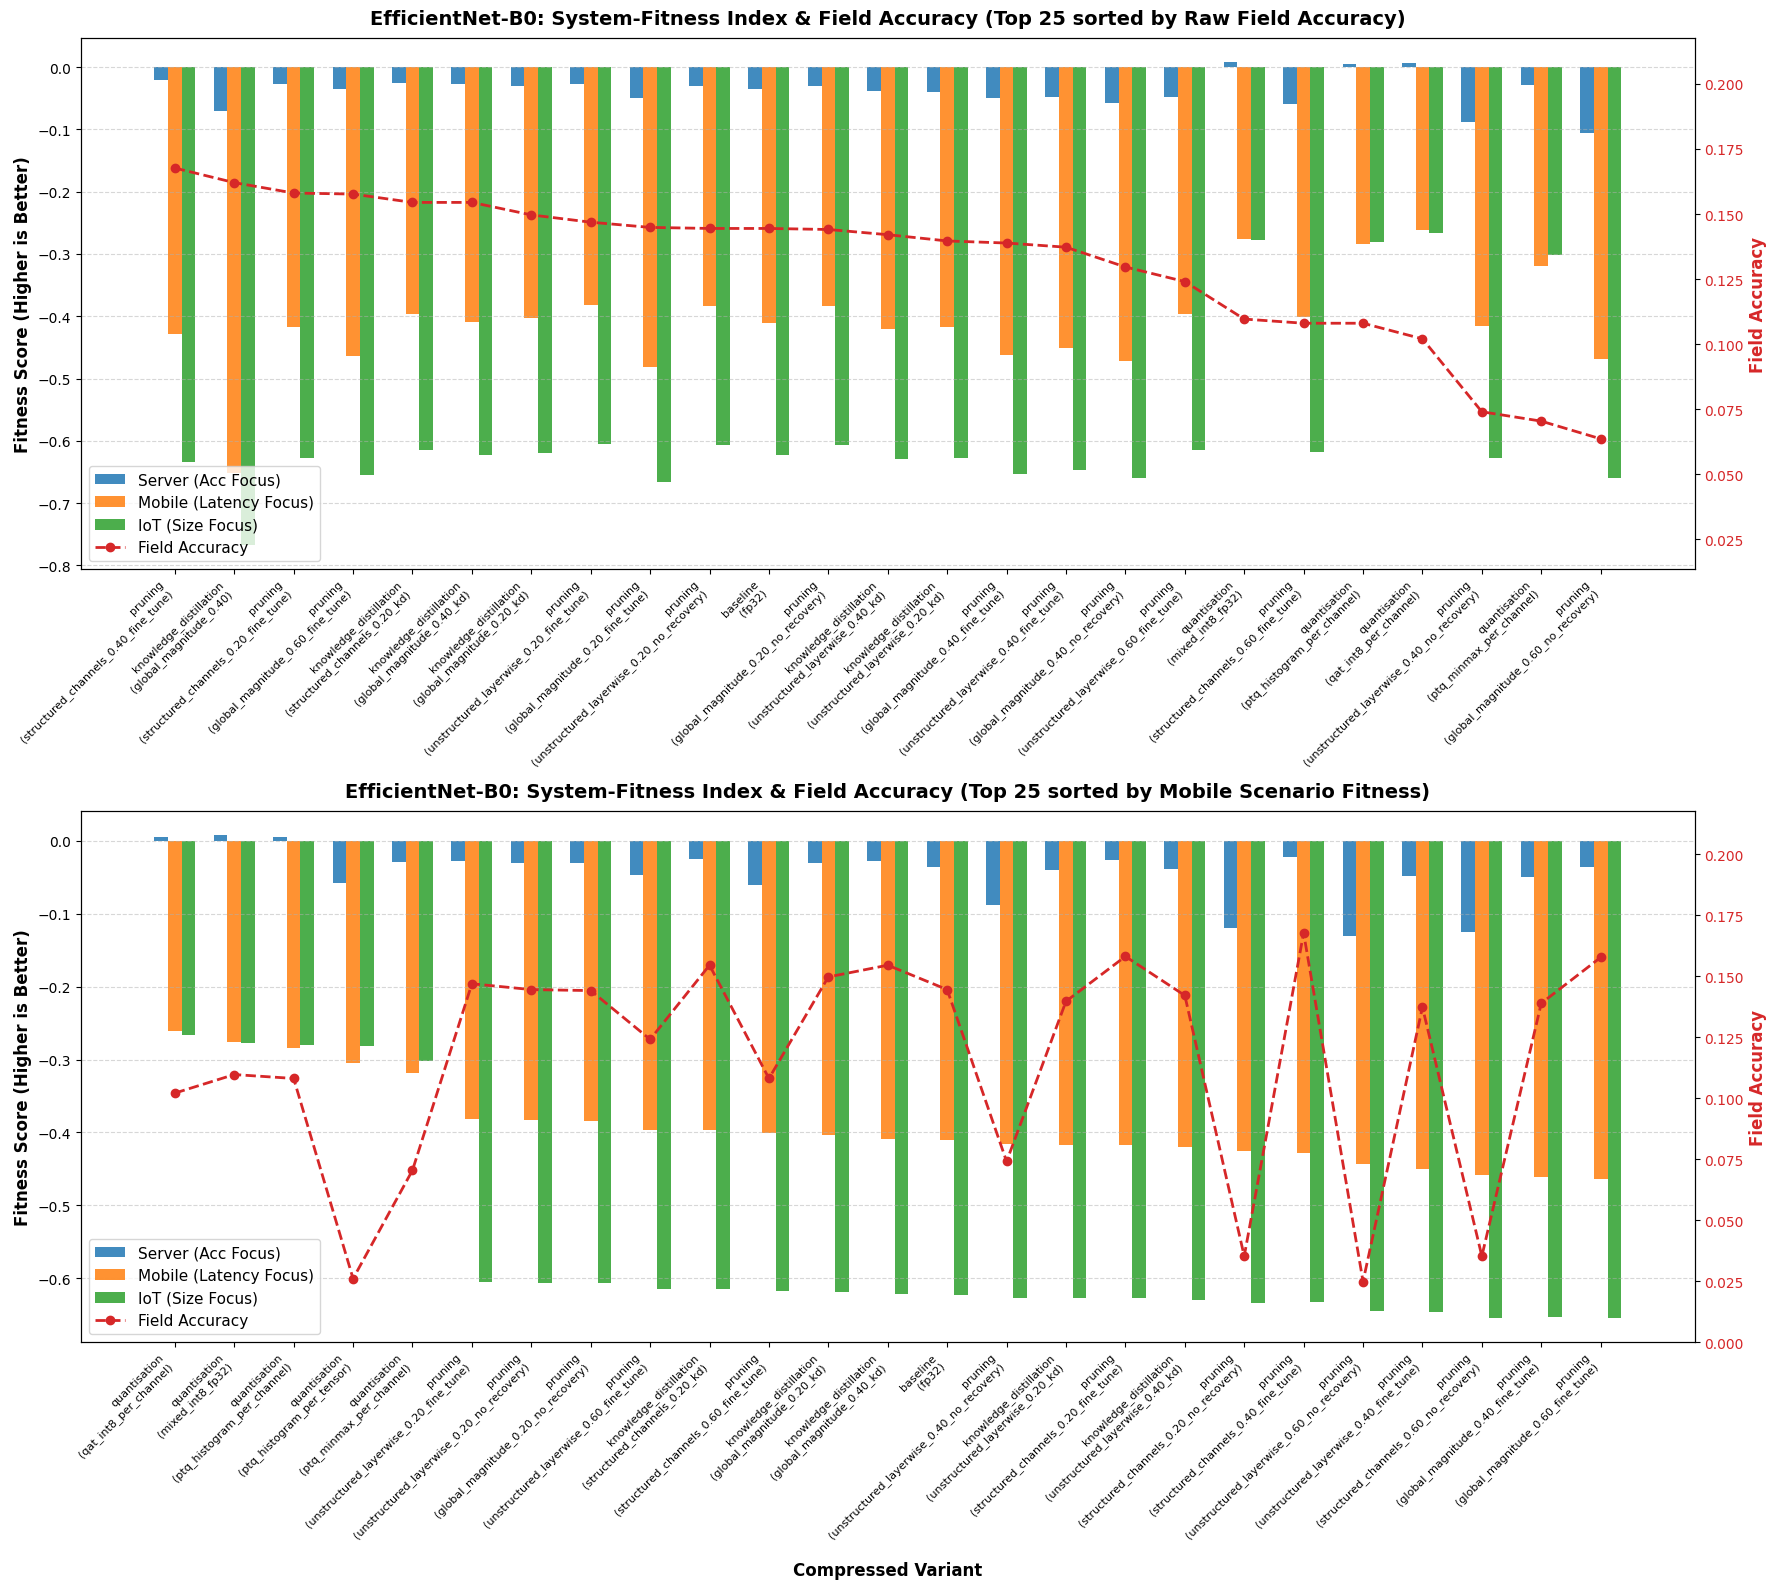

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_results = pd.read_csv(results_path)
    df_eff = df_results[df_results['architecture'] == 'efficientnet_b0'].copy()

    # Define normalization limits based on EfficientNet dataset maximums
    max_lat = df_eff['cpu_latency_mean_ms'].max()
    max_size = df_eff['model_size_mb'].max()

    # Calculate scores
    def calc_fitness(row, w_acc, w_lat, w_size):
        acc_score = row['field_accuracy']
        lat_score = row['cpu_latency_mean_ms'] / max_lat if max_lat > 0 else 1.0
        size_score = row['model_size_mb'] / max_size if max_size > 0 else 1.0
        return w_acc * acc_score - w_lat * lat_score - w_size * size_score

    df_eff['Server Scenario'] = df_eff.apply(lambda r: calc_fitness(r, 0.8, 0.1, 0.1), axis=1)
    df_eff['Mobile Scenario'] = df_eff.apply(lambda r: calc_fitness(r, 0.3, 0.5, 0.2), axis=1)
    df_eff['IoT Scenario'] = df_eff.apply(lambda r: calc_fitness(r, 0.2, 0.3, 0.5), axis=1)

    # --- Graph 1: Sorted by Pure Field Accuracy ---
    df_plot_acc = df_eff.sort_values(by=['field_accuracy', 'cpu_latency_mean_ms'], ascending=[False, True]).head(25).copy()
    df_plot_acc['label'] = df_plot_acc['method'] + '\n(' + df_plot_acc['variant'].str.replace('_partial', '') + ')'

    fig, (ax_acc1, ax_mob1) = plt.subplots(2, 1, figsize=(18, 16))

    x = np.arange(len(df_plot_acc))
    width = 0.23

    # Plot 1 (Accuracy Sorted) Primary Y-axis
    ax_acc1.bar(x - width, df_plot_acc['Server Scenario'], width, label='Server (Acc Focus)', color='#1f77b4', alpha=0.85)
    ax_acc1.bar(x, df_plot_acc['Mobile Scenario'], width, label='Mobile (Latency Focus)', color='#ff7f0e', alpha=0.85)
    ax_acc1.bar(x + width, df_plot_acc['IoT Scenario'], width, label='IoT (Size Focus)', color='#2ca02c', alpha=0.85)
    ax_acc1.set_ylabel('Fitness Score (Higher is Better)', fontsize=12, fontweight='bold')
    ax_acc1.set_title('EfficientNet-B0: System-Fitness Index & Field Accuracy (Top 25 sorted by Raw Field Accuracy)', fontsize=14, fontweight='bold', pad=10)
    ax_acc1.set_xticks(x)
    ax_acc1.set_xticklabels(df_plot_acc['label'], rotation=45, ha='right', fontsize=8)
    ax_acc1.grid(axis='y', linestyle='--', alpha=0.5)

    # Plot 1 Secondary Y-axis
    ax_acc2 = ax_acc1.twinx()
    ax_acc2.plot(x, df_plot_acc['field_accuracy'], color='#d62728', marker='o', markersize=6, linewidth=2.0, linestyle='--', label='Field Accuracy')
    ax_acc2.set_ylabel('Field Accuracy', color='#d62728', fontsize=12, fontweight='bold')
    ax_acc2.tick_params(axis='y', labelcolor='#d62728')
    min_acc = max(0.0, df_plot_acc['field_accuracy'].min() - 0.05)
    max_acc = min(1.0, df_plot_acc['field_accuracy'].max() + 0.05)
    ax_acc2.set_ylim(min_acc, max_acc)

    lines, labels = ax_acc1.get_legend_handles_labels()
    lines2, labels2 = ax_acc2.get_legend_handles_labels()
    ax_acc1.legend(lines + lines2, labels + labels2, loc='lower left', fontsize=11)

    # --- Graph 2: Sorted by Mobile Scenario Fitness ---
    df_plot_mob = df_eff.sort_values(by=['Mobile Scenario', 'field_accuracy'], ascending=[False, False]).head(25).copy()
    df_plot_mob['label'] = df_plot_mob['method'] + '\n(' + df_plot_mob['variant'].str.replace('_partial', '') + ')'

    # Plot 2 (Mobile Sorted) Primary Y-axis
    ax_mob1.bar(x - width, df_plot_mob['Server Scenario'], width, label='Server (Acc Focus)', color='#1f77b4', alpha=0.85)
    ax_mob1.bar(x, df_plot_mob['Mobile Scenario'], width, label='Mobile (Latency Focus)', color='#ff7f0e', alpha=0.85)
    ax_mob1.bar(x + width, df_plot_mob['IoT Scenario'], width, label='IoT (Size Focus)', color='#2ca02c', alpha=0.85)
    ax_mob1.set_ylabel('Fitness Score (Higher is Better)', fontsize=12, fontweight='bold')
    ax_mob1.set_xlabel('Compressed Variant', fontsize=12, fontweight='bold', labelpad=15)
    ax_mob1.set_title('EfficientNet-B0: System-Fitness Index & Field Accuracy (Top 25 sorted by Mobile Scenario Fitness)', fontsize=14, fontweight='bold', pad=10)
    ax_mob1.set_xticks(x)
    ax_mob1.set_xticklabels(df_plot_mob['label'], rotation=45, ha='right', fontsize=8)
    ax_mob1.grid(axis='y', linestyle='--', alpha=0.5)

    # Plot 2 Secondary Y-axis
    ax_mob2 = ax_mob1.twinx()
    ax_mob2.plot(x, df_plot_mob['field_accuracy'], color='#d62728', marker='o', markersize=6, linewidth=2.0, linestyle='--', label='Field Accuracy')
    ax_mob2.set_ylabel('Field Accuracy', color='#d62728', fontsize=12, fontweight='bold')
    ax_mob2.tick_params(axis='y', labelcolor='#d62728')
    min_acc_m = max(0.0, df_plot_mob['field_accuracy'].min() - 0.05)
    max_acc_m = min(1.0, df_plot_mob['field_accuracy'].max() + 0.05)
    ax_mob2.set_ylim(min_acc_m, max_acc_m)

    lines_m, labels_m = ax_mob1.get_legend_handles_labels()
    lines2_m, labels2_m = ax_mob2.get_legend_handles_labels()
    ax_mob1.legend(lines_m + lines2_m, labels_m + labels2_m, loc='lower left', fontsize=11)

    plt.tight_layout()
    plt.show()
else:
    print("Consolidated results CSV not found! Please run the consolidation cells first.")

##Top performers stacking

### EfficientNet_B0

### stack 9 models with a mix of high fitness score vs accuracy trade off

In [ ]:
import torch
import torch.nn as nn
from pathlib import Path
from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx
from torch.ao.quantization import QConfigMapping

print("=== OPTION 1: 9-Model Full Stacking Ensemble ===")

class EnsembleStack(nn.Module):
    def __init__(self, arch, model_paths, num_classes=26):
        super().__init__()
        self.models = nn.ModuleList()
        for path in model_paths:
            state_dict = torch.load(path, map_location='cpu')
            if 'model_state_dict' in state_dict:
                state_dict = state_dict['model_state_dict']

            m = build_model(arch)

            # Detect quantization by checking if any loaded tensor is a quantized parameter type
            is_quantized = any(isinstance(v, torch.Tensor) and v.is_quantized for v in state_dict.values())

            if is_quantized:
                # Recreate the exact FX quantization structure
                mapping = QConfigMapping().set_global(ptq_qconfig('histogram', True))
                if 'mixed' in str(path):
                    mapping = mapping.set_module_name('classifier', None)
                prepared = prepare_fx(m.cpu().eval(), mapping, example_inputs)
                m = convert_fx(prepared).eval()

            # Load the state dict using the correctly-structured model
            m.load_state_dict(state_dict, strict=True)
            m.eval()
            self.models.append(m)

    def forward(self, x):
        # Run inference across all sub-models and average the output logits
        logits = [model(x) for model in self.models]
        return torch.stack(logits, dim=0).mean(dim=0)

model_keys = [
    'efficientnet_b0_quantisation_qat_int8_per_channel_partial.pth',
    'efficientnet_b0_quantisation_mixed_int8_fp32_partial.pth',
    'efficientnet_b0_quantisation_ptq_histogram_per_channel_partial.pth',
    'efficientnet_b0_pruning_unstructured_layerwise_0.20_fine_tune_partial.pth',
    'efficientnet_b0_pruning_structured_channels_0.40_fine_tune_partial.pth',
    'efficientnet_b0_pruning_global_magnitude_0.20_no_recovery_partial.pth',
    'efficientnet_b0_knowledge_distillation_structured_channels_0.20_kd_partial.pth',
    'efficientnet_b0_knowledge_distillation_global_magnitude_0.40_kd_partial.pth',
    'efficientnet_b0_knowledge_distillation_unstructured_layerwise_0.40_kd_partial.pth'
]

local_valid_paths = [OUTPUT_MODEL_DIR / k for k in model_keys if (OUTPUT_MODEL_DIR / k).exists()]

if len(local_valid_paths) == 9:
    print("All 9 checkpoints are present on disk. Initializing the 9-model Stack...")
    full_stack = EnsembleStack(arch='efficientnet_b0', model_paths=local_valid_paths)
    full_stack = full_stack.to(device).eval()

    # Benchmarking latency
    print("Measuring CPU Latency for 9-Model Stack...")
    lat_mean, lat_std = cpu_latency_ms(full_stack, test_loader.dataset)

    # Evaluating test split
    print("Evaluating on Test Split...")
    test_metrics = evaluate_split(full_stack, test_loader, device)

    # Evaluating field split
    print("Evaluating on Field Split...")
    field_metrics = evaluate_split(full_stack, field_loader, device)

    print("\n--- 9-Model Stack Evaluation Results ---")
    print(f"Test Accuracy  : {test_metrics['accuracy']:.4%}")
    print(f"Field Accuracy : {field_metrics['accuracy']:.4%}")
    print(f"CPU Latency    : {lat_mean:.2f} ms ± {lat_std:.2f} ms")
else:
    print(f"Warning: Only {len(local_valid_paths)}/9 checkpoints were found on disk.")

=== OPTION 1: 9-Model Full Stacking Ensemble ===
All 9 checkpoints are present on disk. Initializing the 9-model Stack...


/tmp/ipykernel_1272/1062490738.py:28: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = prepare_fx(m.cpu().eval(), mapping, example_inputs)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/fx/utils.py:994: UserWarning: QConfig must specify a FixedQParamsObserver or a FixedQParamsFakeQuantize for fixed qparams ops, ignoring QConfig(activation=functools

Measuring CPU Latency for 9-Model Stack...
Evaluating on Test Split...


  0%|          | 0/168 [00:00<?, ?it/s]

Evaluating on Field Split...


  0%|          | 0/79 [00:00<?, ?it/s]


--- 9-Model Stack Evaluation Results ---
Test Accuracy  : 98.3631%
Field Accuracy : 14.4058%
CPU Latency    : 639.08 ms ± 260.24 ms


###choose one model per compression technique to stack together

In [ ]:
import torch
import torch.nn as nn
from pathlib import Path
from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx
from torch.ao.quantization import QConfigMapping

print("=== OPTION 2: 3-Model Selective Hybrid Stacking Ensemble ===")

class EnsembleStack(nn.Module):
    def __init__(self, arch, model_paths, num_classes=26):
        super().__init__()
        self.models = nn.ModuleList()
        for path in model_paths:
            state_dict = torch.load(path, map_location='cpu')
            if 'model_state_dict' in state_dict:
                state_dict = state_dict['model_state_dict']

            m = build_model(arch)
            is_quantized = any(isinstance(v, torch.Tensor) and v.is_quantized for v in state_dict.values())

            if is_quantized:
                # Structurally prepare the model for PyTorch FX Quantization to accept quantized weights
                mapping = QConfigMapping().set_global(ptq_qconfig('histogram', True))
                if 'mixed' in str(path):
                    mapping = mapping.set_module_name('classifier', None)
                prepared = prepare_fx(m.cpu().eval(), mapping, example_inputs)
                m = convert_fx(prepared).eval()
                m.load_state_dict(state_dict, strict=True)
            else:
                # Non-quantized model (e.g. standard FP32 pruned or KD model)
                m.load_state_dict(state_dict, strict=True)

            m.eval()
            self.models.append(m)

    def forward(self, x):
        logits = [model(x) for model in self.models]
        return torch.stack(logits, dim=0).mean(dim=0)

# Force dataloaders to run sequentially with num_workers=0 to prevent background worker crashes
test_loader = make_loader(test_df, eval_tf, shuffle=False)
field_loader = make_loader(field_df, eval_tf, shuffle=False)

selective_keys = [
    'efficientnet_b0_quantisation_qat_int8_per_channel_partial.pth',
    'efficientnet_b0_pruning_unstructured_layerwise_0.20_fine_tune_partial.pth',
    'efficientnet_b0_knowledge_distillation_structured_channels_0.20_kd_partial.pth'
]

selective_paths = [OUTPUT_MODEL_DIR / k for k in selective_keys if (OUTPUT_MODEL_DIR / k).exists()]

if len(selective_paths) == 3:
    print(f"All 3 targeted hybrid checkpoints found. Initializing the 3-model Hybrid Stack...")
    hybrid_stack = EnsembleStack(arch='efficientnet_b0', model_paths=selective_paths)
    hybrid_stack = hybrid_stack.to(device).eval()

    # Benchmarking latency
    print("Measuring CPU Latency for 3-Model Stack...")
    hybrid_lat_mean, hybrid_lat_std = cpu_latency_ms(hybrid_stack, test_loader.dataset)

    # Evaluating test split
    print("Evaluating on Test Split...")
    hybrid_test_metrics = evaluate_split(hybrid_stack, test_loader, device)

    # Evaluating field split
    print("Evaluating on Field Split...")
    hybrid_field_metrics = evaluate_split(hybrid_stack, field_loader, device)

    print("\n--- 3-Model Hybrid Stack Evaluation Results ---")
    print(f"Test Accuracy  : {hybrid_test_metrics['accuracy']:.4%}")
    print(f"Field Accuracy : {hybrid_field_metrics['accuracy']:.4%}")
    print(f"CPU Latency    : {hybrid_lat_mean:.2f} ms ± {hybrid_lat_std:.2f} ms")
else:
    print(f"Warning: Only found {len(selective_paths)}/3 targeted hybrid checkpoints on disk.")

=== OPTION 2: 3-Model Selective Hybrid Stacking Ensemble ===
All 3 targeted hybrid checkpoints found. Initializing the 3-model Hybrid Stack...


/tmp/ipykernel_1272/551396897.py:26: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = prepare_fx(m.cpu().eval(), mapping, example_inputs)
/usr/local/lib/python3.13/dist-packages/torch/ao/quantization/fx/utils.py:994: UserWarning: QConfig must specify a FixedQParamsObserver or a FixedQParamsFakeQuantize for fixed qparams ops, ignoring QConfig(activation=functools.

Measuring CPU Latency for 3-Model Stack...
Evaluating on Test Split...


  0%|          | 0/168 [00:00<?, ?it/s]

Evaluating on Field Split...


  0%|          | 0/79 [00:00<?, ?it/s]


--- 3-Model Hybrid Stack Evaluation Results ---
Test Accuracy  : 98.5491%
Field Accuracy : 13.8455%
CPU Latency    : 174.38 ms ± 29.86 ms
